# Image Captioning on CIFAR-100 (from scratch)

**Goal:** build an image-to-text model that takes a 32×32 CIFAR-100 image and generates a short caption. The captioner, its DCGAN-pretrained encoder and the Transformer decoder are implemented from scratch in PyTorch (no pre-trained captioning model). *Stable Diffusion* To guide the model to learn better features, we used an open-source text-to-image model to create extra *training* images.

| Section | Content |
|---|---|
| 0 | Setup (works locally and on Google Colab) |
| 1 | Load CIFAR-100, merge, stratified 60/20/20 split |
| 2 | Caption generation (from the coarse and fine labels only) and vocabulary |
| 3 | DCGAN from scratch, and a linear-probe test of its features |
| 4 | Stable Diffusion: synthetic training images |
| 5 | Captioning model (CNN encoder + Transformer decoder) |
| 6 | Training procedure, decoding and evaluation metrics |
| 7 | Experiments on the validation set: what do the DCGAN and Stable Diffusion contribute? |
| 8 | Evaluation on the test set, example captions, error analysis |


**The diagram below shows the overall image captioning Pipeline.**

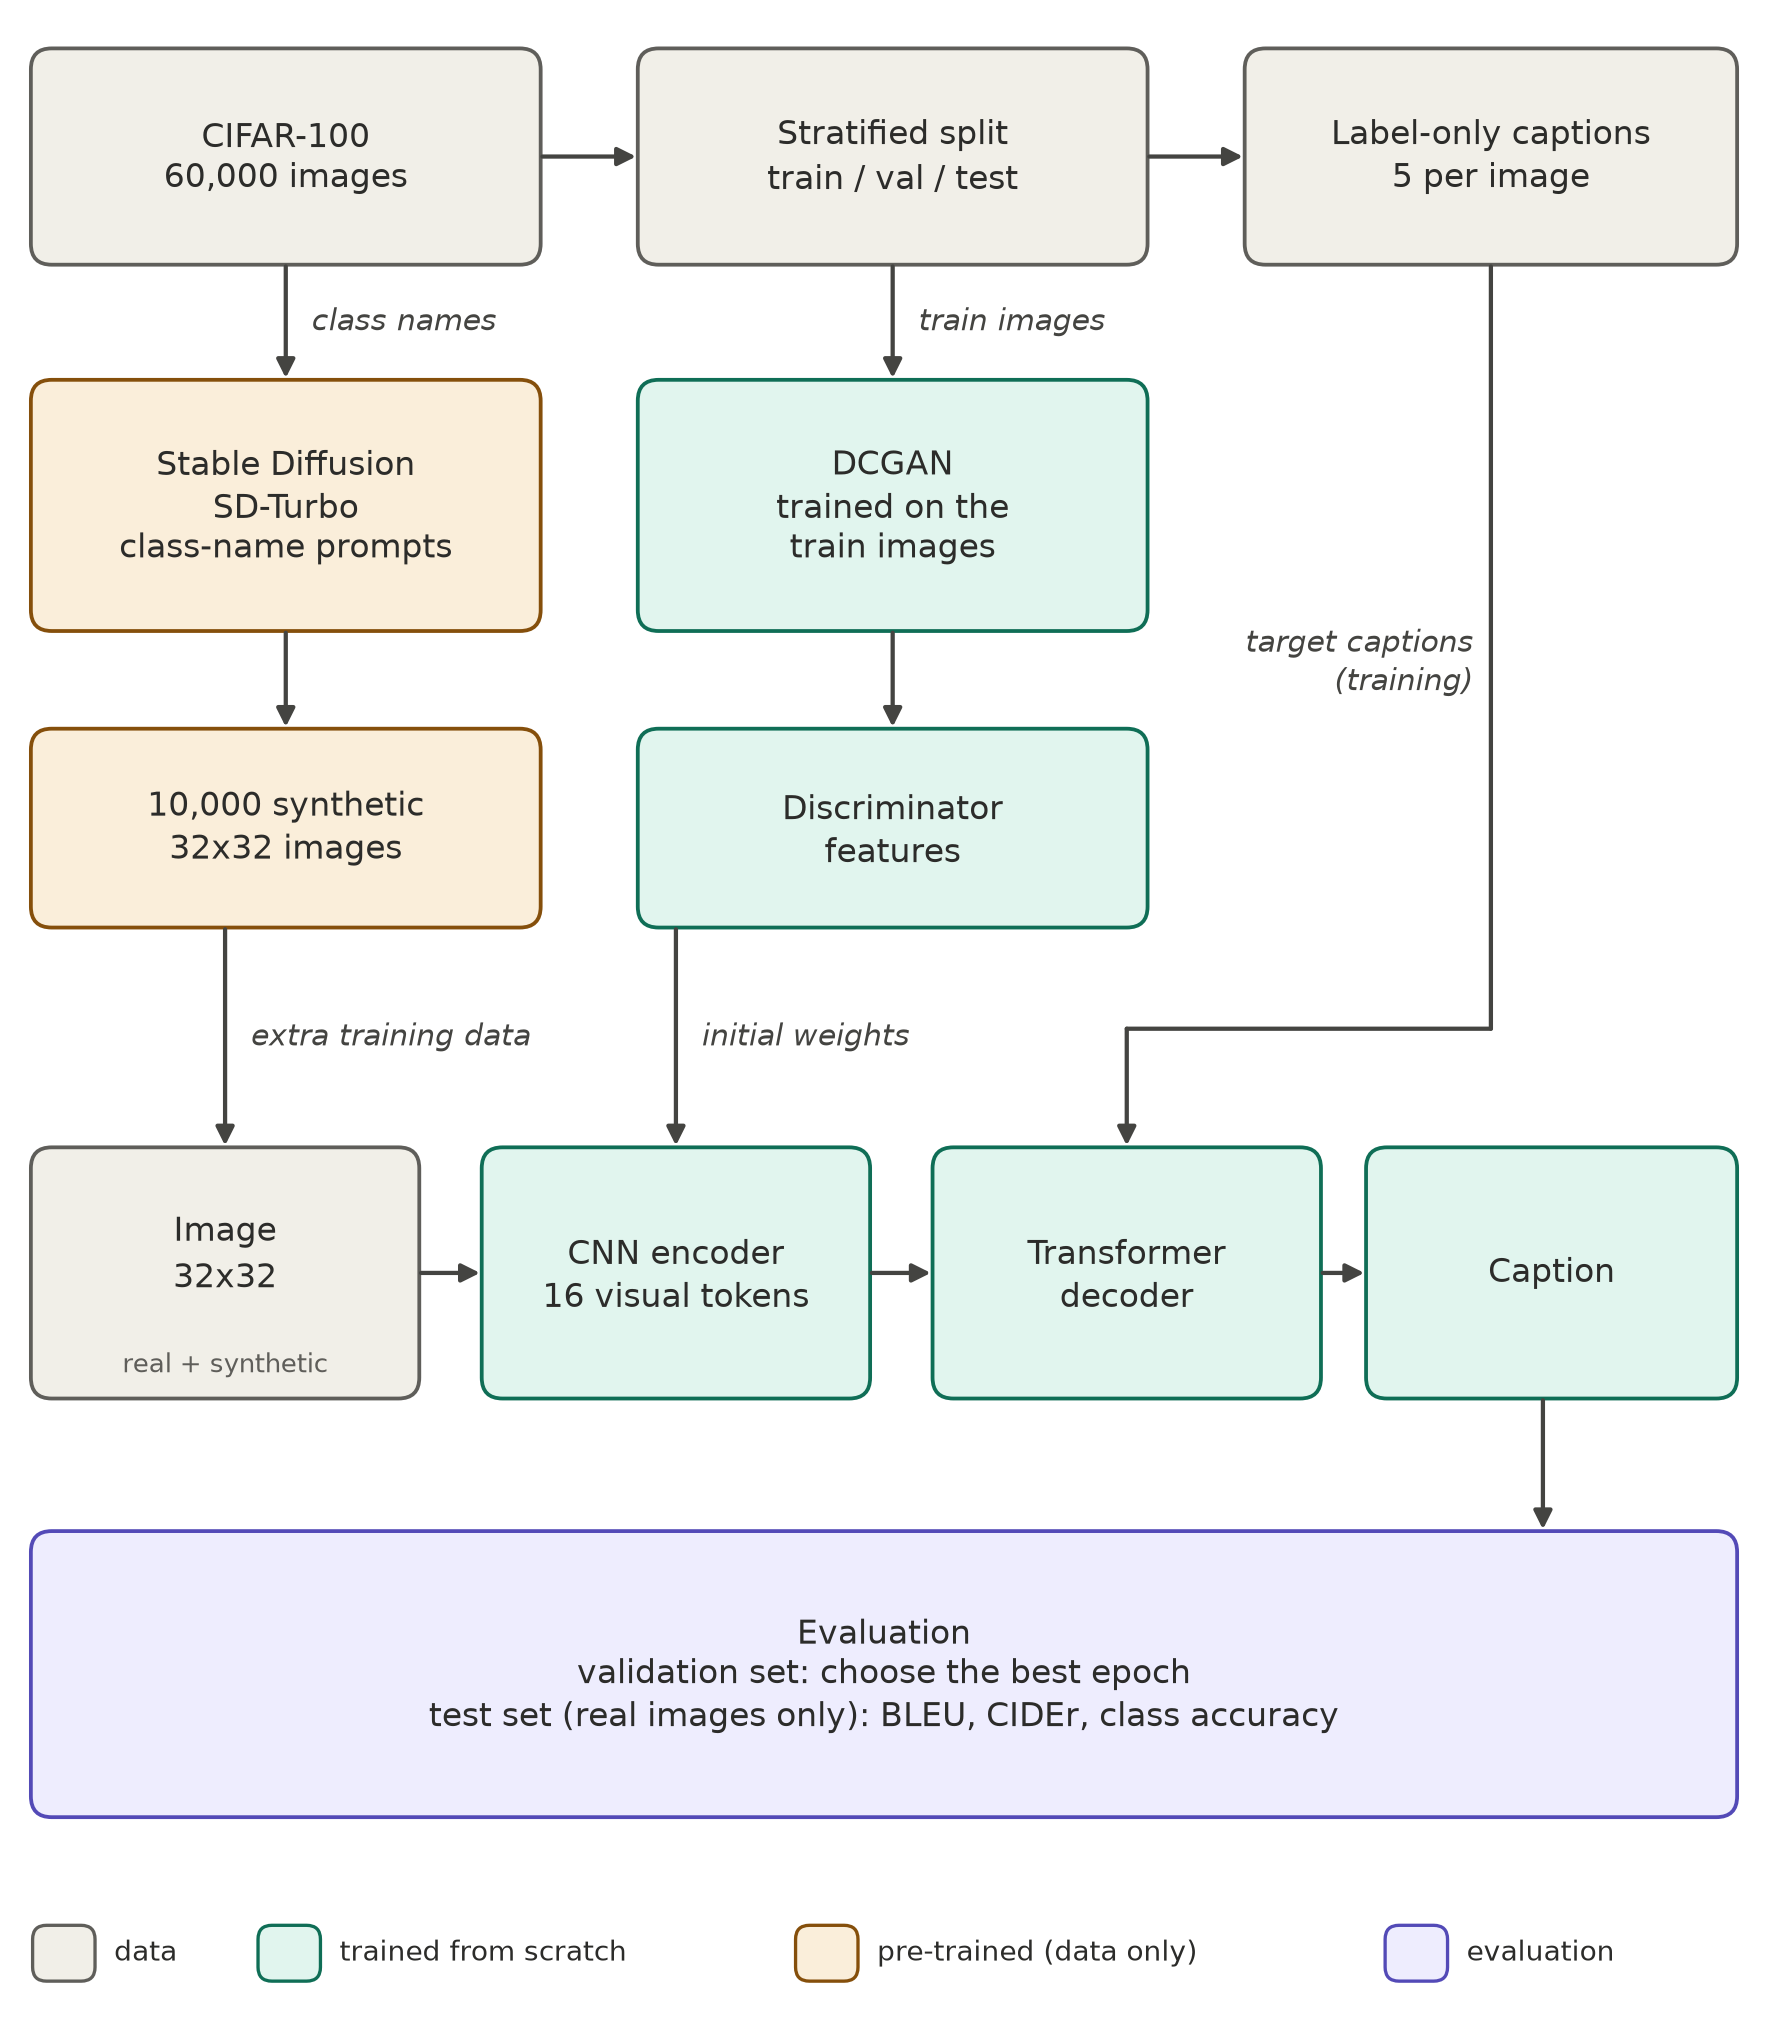


**How to run:** `Runtime → Run all`. On Colab, select a GPU runtime first (`Runtime → Change runtime type → T4 GPU`). Set the `TRAIN_*` flags in Section 0 to `False` to load saved checkpoints from `checkpoints/` instead of retraining.


## 0. Env Setup

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules

# ---------------------------------------------------------------- Parameters
LOCAL_GPU = "1"           # GPU index on the local multi-GPU machine (GPU 0 is shared); ignored on Colab, which has one GPU
SEED = 42                 # seed for the data split, DCGAN training, linear probe and Stable Diffusion sampling (captioner runs use SEEDS, Section 7)
TRAIN_DCGAN = False       # True: retrain the DCGAN even if checkpoints/dcgan.pt exists (then also set TRAIN_CAPTIONERS = True, or saved captioners keep the old DCGAN weights)
PLOT_FONT = 13            # base font size of all figures (titles are +2; labels inside plots are set relative to it)
TRAIN_CAPTIONERS = False  # True: retrain all 15 captioners (Section 7) even if checkpoints/captioners/*.pt exist
# ------------------------------------------------------------------------------

if not IN_COLAB:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", LOCAL_GPU)

import re, math, time, random, pickle
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": PLOT_FONT, "axes.titlesize": PLOT_FONT + 2, "axes.labelsize": PLOT_FONT + 1,
                     "xtick.labelsize": PLOT_FONT, "ytick.labelsize": PLOT_FONT, "legend.fontsize": PLOT_FONT})

# project folders (created if missing): data/ = datasets, checkpoints/ = saved models, outputs/ = figures and results
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
CKPT_DIR = ROOT / "checkpoints"
OUT_DIR = ROOT / "outputs"
for d in (DATA_DIR, CKPT_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    """Seed Python, NumPy and PyTorch (CPU and GPU) so that runs are reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True   # let cuDNN pick the fastest convolution algorithms

gpu = f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""
print(f"Colab: {IN_COLAB} | torch {torch.__version__} | device: {DEVICE}{gpu}")
print(f"Project root: {ROOT}")


Colab: False | torch 2.12.1+cu130 | device: cuda (Quadro RTX 8000)
Project root: /home/local/AD/malam4/Documents/projects/building_image_captioning_model_from_scratch


## 1. Data: load CIFAR-100 and split 60/20/20

CIFAR-100 ships as 50,000 train + 10,000 test images. The our task asks for a 60/20/20 split, so we merge both into one pool of 60,000 images and split it ourselves.

The split is **stratified by fine class**: each of the 100 classes contributes exactly 360 train, 120 validation and 120 test images, so every set has the same class balance. The indices are saved to `data/split_indices.npz` so the split is identical on every run.

We read the original pickle files directly because `torchvision` only exposes the fine labels, and we also need the 20 coarse (superclass) labels.

In [2]:
# download CIFAR-100 once (50,000 train + 10,000 test images); both parts are merged into one pool of 60,000 below
torchvision.datasets.CIFAR100(DATA_DIR, train=True, download=True)
torchvision.datasets.CIFAR100(DATA_DIR, train=False, download=True)

def load_pickle(name):
    """Load one file ("train", "test" or "meta") of the original CIFAR-100 pickle archive."""
    with open(DATA_DIR / "cifar-100-python" / name, "rb") as f:
        return pickle.load(f, encoding="latin1")

meta = load_pickle("meta")
FINE_NAMES = meta["fine_label_names"]
COARSE_NAMES = meta["coarse_label_names"]

parts = [load_pickle("train"), load_pickle("test")]
images = np.concatenate([p["data"] for p in parts]).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
fine_labels = np.concatenate([p["fine_labels"] for p in parts]).astype(np.int64)
coarse_labels = np.concatenate([p["coarse_labels"] for p in parts]).astype(np.int64)

# FINE_TO_COARSE[k] = coarse class (superclass) of fine class k
FINE_TO_COARSE = np.zeros(len(FINE_NAMES), dtype=np.int64)
FINE_TO_COARSE[fine_labels] = coarse_labels
assert (FINE_TO_COARSE[fine_labels] == coarse_labels).all(), "each fine class must map to one coarse class"

print(f"images: {images.shape} {images.dtype}")
print(f"{len(FINE_NAMES)} fine classes, {len(COARSE_NAMES)} coarse classes")

images: (60000, 32, 32, 3) uint8
100 fine classes, 20 coarse classes


In [3]:
# ---------------------------------------------------------------- Parameters
SPLIT_FRACTIONS = (0.6, 0.2, 0.2)   # share of every class for train / validation / test (only the first two are used; test gets the rest)
# The split also depends on SEED (Section 0). Both are ignored while data/split_indices.npz exists: delete that file to re-split.
# ------------------------------------------------------------------------------

def stratified_split(labels, fractions=SPLIT_FRACTIONS, seed=SEED):
    """Split image indices into train/val/test so that every class contributes the same fractions; returns sorted index arrays."""
    rng = np.random.default_rng(seed)
    out = {"train": [], "val": [], "test": []}
    for c in np.unique(labels):
        idx = rng.permutation(np.flatnonzero(labels == c))
        n_train = int(round(fractions[0] * len(idx)))
        n_val = int(round(fractions[1] * len(idx)))
        out["train"].append(idx[:n_train])
        out["val"].append(idx[n_train:n_train + n_val])
        out["test"].append(idx[n_train + n_val:])
    return {k: np.sort(np.concatenate(v)) for k, v in out.items()}

split_path = DATA_DIR / "split_indices.npz"
if split_path.exists():
    SPLITS = dict(np.load(split_path))
    print(f"Loaded split from {split_path}")
else:
    SPLITS = stratified_split(fine_labels)
    np.savez(split_path, **SPLITS)
    print(f"Created split and saved to {split_path}")

for name, idx in SPLITS.items():
    per_class = np.bincount(fine_labels[idx], minlength=100)
    print(f"{name:5s}: {len(idx):6d} images ({len(idx) / len(images):.0%}) | per class min/max = {per_class.min()}/{per_class.max()}")

all_idx = np.concatenate(list(SPLITS.values()))
assert len(np.unique(all_idx)) == len(images), "splits must be disjoint and cover every image"

Loaded split from /home/local/AD/malam4/Documents/projects/building_image_captioning_model_from_scratch/data/split_indices.npz
train:  36000 images (60%) | per class min/max = 360/360
val  :  12000 images (20%) | per class min/max = 120/120
test :  12000 images (20%) | per class min/max = 120/120


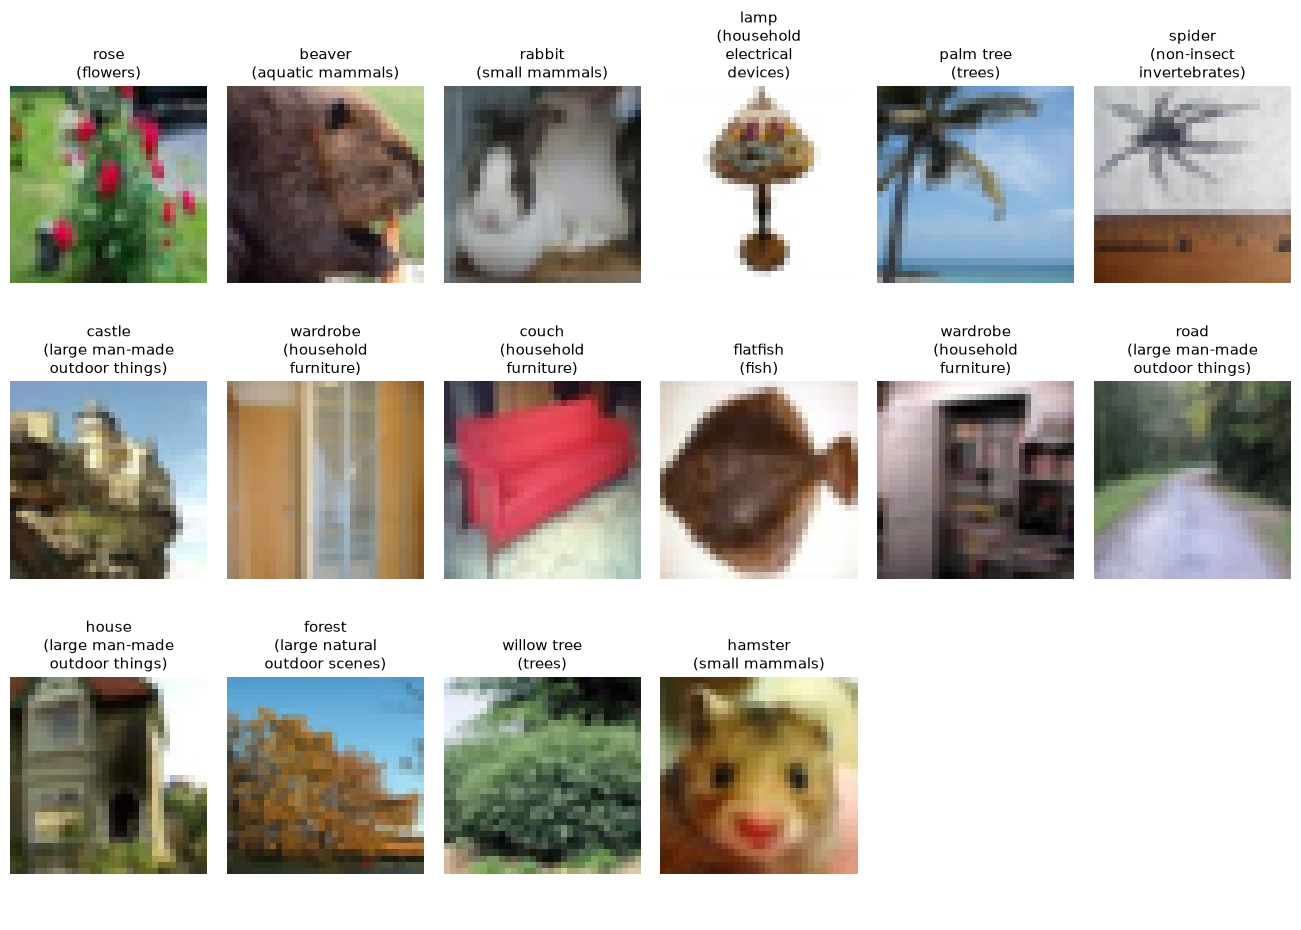

In [4]:
# ---------------------------------------------------------------- Parameters
N_SAMPLES = 16   # random training images shown below
SAMPLE_SEED = 0  # seed of the random choice, so the same images are shown on every run
# ------------------------------------------------------------------------------

def show_grid(imgs, titles=None, ncols=8, size=1.6, fontsize=PLOT_FONT - 2, path=None, title_height=0.35):
    """Show `imgs` in a grid with `ncols` columns and `size` inches per cell (optional per-image `titles` drawn at `fontsize`, with `title_height` extra inches per row); also saves the figure to `path` if given."""
    n = len(imgs)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * (size + title_height * (titles is not None))))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for i, ax in enumerate(np.atleast_1d(axes).ravel()[:n]):
        ax.imshow(imgs[i])
        if titles is not None:
            ax.set_title(titles[i], fontsize=fontsize)
    plt.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

rng = np.random.default_rng(SAMPLE_SEED)
sample = rng.choice(SPLITS["train"], N_SAMPLES, replace=False)
import textwrap
show_grid(images[sample],
          [f"{FINE_NAMES[fine_labels[i]].replace('_', ' ')}\n" + textwrap.fill(f"({COARSE_NAMES[coarse_labels[i]].replace('_', ' ')})", 18) for i in sample],
          ncols=6, size=2.2, title_height=1.0, path=OUT_DIR / "cifar100_samples.png")   # room for 3-line titles

### Tensors and augmentation

Images are scaled to **[-1, 1]**, matching the generator's `tanh` output in the DCGAN. The whole dataset fits in GPU memory (about 0.7 GB as float32), so batches are sliced directly from GPU tensors instead of going through a `DataLoader`, and augmentation (random horizontal flip + random crop with 4-pixel reflect padding) is done on the GPU.

{'train': (36000, 3, 32, 32), 'val': (12000, 3, 32, 32), 'test': (12000, 3, 32, 32)} range [-1.0, 1.0]


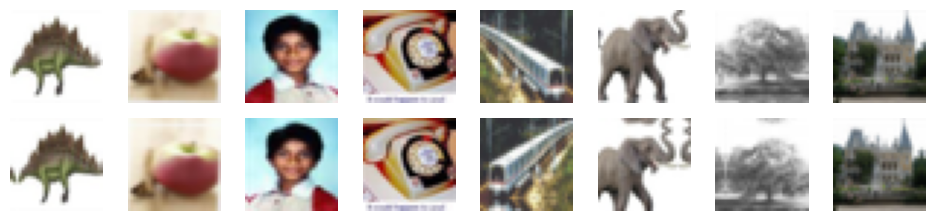

Top row: original, bottom row: augmented


In [5]:
# ---------------------------------------------------------------- Parameters
AUG_PAD = 4   # reflect padding in pixels: the random crop shifts an image by up to +-AUG_PAD pixels
# ------------------------------------------------------------------------------

def to_tensor(imgs_uint8):
    """uint8 images (N, 32, 32, 3) -> float tensor (N, 3, 32, 32) rescaled from [0, 255] to [-1, 1] (the range of the DCGAN's tanh output)."""
    return torch.from_numpy(imgs_uint8).permute(0, 3, 1, 2).float().div(127.5).sub(1.0)

def to_image(x):
    """Inverse of to_tensor for plotting: tensor in [-1, 1] -> numpy images (N, 32, 32, 3) in [0, 1]."""
    return ((x.clamp(-1, 1) + 1) / 2).permute(0, 2, 3, 1).cpu().numpy()

X = {k: to_tensor(images[idx]) for k, idx in SPLITS.items()}
Y_FINE = {k: torch.from_numpy(fine_labels[idx]) for k, idx in SPLITS.items()}
Y_COARSE = {k: torch.from_numpy(coarse_labels[idx]) for k, idx in SPLITS.items()}

def augment(x, pad=AUG_PAD):
    """Random horizontal flip (p = 0.5) and random crop of a reflect-padded copy, drawn independently per image and computed on the device of x; same shape as x."""
    n, c, h, w = x.shape
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    padded = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    top = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    left = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    # pick a different 32x32 window for every image with advanced indexing
    rows = (top[:, None] + torch.arange(h, device=x.device))[:, None, :, None]
    cols = (left[:, None] + torch.arange(w, device=x.device))[:, None, None, :]
    batch = torch.arange(n, device=x.device)[:, None, None, None]
    chan = torch.arange(c, device=x.device)[None, :, None, None]
    return padded[batch, chan, rows, cols]

print({k: tuple(v.shape) for k, v in X.items()}, f"range [{X['train'].min():.1f}, {X['train'].max():.1f}]")
demo = X["train"][:8]
show_grid(np.concatenate([to_image(demo), to_image(augment(demo))]), ncols=8, size=1.2)
print("Top row: original, bottom row: augmented")

## 2. Captions and vocabulary

CIFAR-100 has **no captions**, only a fine label (e.g. `maple_tree`) and a coarse label (e.g. `trees`). We therefore build the captions from these two labels.

Every image gets **5 reference captions** from fixed templates (as COCO has 5 per image). Three templates mention only the fine class, two also mention the coarse category:

```
a photo of a maple tree
a picture of a maple tree
a maple tree from the trees category
an image showing a maple tree
a maple tree belonging to the trees category
```

During training one reference is sampled at random per image and step. During evaluation the generated caption is compared against all 5. Because the captions are label-based, a good captioner must (1) recognise the object class, (2) choose a template and (3) state a coarse category that is consistent with the class it recognised. Section 6 defines metrics for (1) (fine accuracy) and (3) (category consistency); the choice of template is not scored separately, because every template is a valid reference. This is a limitation we discuss in the results: the captions describe *what* is in the image but nothing about *how* it looks.

In [6]:
FINE_PHRASE = [n.replace("_", " ") for n in FINE_NAMES]
# coarse phrases for captions; the two superclasses vehicles_1 / vehicles_2 are both written "vehicles" (so a stated category can match two coarse ids, see COARSE_TOK in Section 6)
COARSE_PHRASE = [re.sub(r"vehicles \d", "vehicles", n.replace("_", " ")) for n in COARSE_NAMES]
USES_THE = {"sea"}   # class names that take "the" instead of a/an

def noun_phrase(noun):
    """Put the article in front of a noun: "a"/"an", or "the" for nouns in USES_THE."""
    if noun in USES_THE:
        return f"the {noun}"
    return f"{'an' if noun[0] in 'aeiou' else 'a'} {noun}"

# the 5 caption templates (f = fine class phrase, c = coarse category phrase)
TEMPLATES = [
    lambda f, c: f"a photo of {noun_phrase(f)}",
    lambda f, c: f"a picture of {noun_phrase(f)}",
    lambda f, c: f"{noun_phrase(f)} from the {c} category",
    lambda f, c: f"an image showing {noun_phrase(f)}",
    lambda f, c: f"{noun_phrase(f)} belonging to the {c} category",
]
N_CAPS = len(TEMPLATES)

def make_captions(fine_id):
    """The 5 reference captions of a fine class (used for real and synthetic images alike)."""
    fine_id = int(fine_id)
    return [t(FINE_PHRASE[fine_id], COARSE_PHRASE[FINE_TO_COARSE[fine_id]]) for t in TEMPLATES]

CAPTIONS = [make_captions(f) for f in fine_labels]   # CAPTIONS[i] = the 5 reference captions of image i

for i in SPLITS["train"][:2]:
    print(f"{FINE_NAMES[fine_labels[i]]} ({COARSE_NAMES[coarse_labels[i]]}):")
    for cap in CAPTIONS[i]:
        print(" -", cap)


dinosaur (reptiles):
 - a photo of a dinosaur
 - a picture of a dinosaur
 - a dinosaur from the reptiles category
 - an image showing a dinosaur
 - a dinosaur belonging to the reptiles category
apple (fruit_and_vegetables):
 - a photo of an apple
 - a picture of an apple
 - an apple from the fruit and vegetables category
 - an image showing an apple
 - an apple belonging to the fruit and vegetables category


### Tokenizer and vocabulary

A word-level tokenizer: lowercase, words (hyphenated words such as `man-made` stay one token) and commas. The vocabulary is built **from training captions only** and has four special tokens: `<pad>` (padding), `<bos>` (start of sentence), `<eos>` (end of sentence) and `<unk>` (unknown word).

In [7]:
TOKEN_RE = re.compile(r"[a-z]+(?:-[a-z]+)*|,")

def tokenize(text):
    """Lowercase a caption and split it into words (hyphenated words stay one token) and commas."""
    return TOKEN_RE.findall(text.lower())

class Vocab:
    """Word-level vocabulary: maps words <-> integer ids; ids 0-3 are the special tokens <pad>, <bos>, <eos>, <unk>."""
    PAD, BOS, EOS, UNK = "<pad>", "<bos>", "<eos>", "<unk>"

    def __init__(self, token_lists):
        """Collect every word that occurs in `token_lists` (sorted) after the 4 special tokens."""
        counts = Counter(t for toks in token_lists for t in toks)
        self.itos = [self.PAD, self.BOS, self.EOS, self.UNK] + sorted(counts)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.pad_id, self.bos_id, self.eos_id, self.unk_id = range(4)

    def __len__(self):
        """Number of tokens, special tokens included."""
        return len(self.itos)

    def encode(self, text, max_len):
        """Caption string -> list of exactly `max_len` ids: <bos>, the words, <eos>, then <pad>."""
        ids = [self.bos_id] + [self.stoi.get(t, self.unk_id) for t in tokenize(text)] + [self.eos_id]
        assert len(ids) <= max_len, f"caption too long: {text}"
        return ids + [self.pad_id] * (max_len - len(ids))

    def decode(self, ids):
        """List/tensor of ids -> caption string; stops at <eos> and skips <pad> and <bos>."""
        words = []
        for i in ids:
            i = int(i)
            if i == self.eos_id:
                break
            if i not in (self.pad_id, self.bos_id):
                words.append(self.itos[i])
        return " ".join(words).replace(" ,", ",")

train_tokens = [tokenize(c) for i in SPLITS["train"] for c in CAPTIONS[i]]
vocab = Vocab(train_tokens)
MAX_LEN = max(len(t) for t in train_tokens) + 2   # longest caption + <bos> + <eos>; every caption is padded to this length

# CAP_IDS[i, k] = ids of reference caption k of image i;  Y_CAPS[split] = the same for the images of one split
CAP_IDS = torch.tensor([[vocab.encode(c, MAX_LEN) for c in caps] for caps in CAPTIONS])
Y_CAPS = {k: CAP_IDS[idx] for k, idx in SPLITS.items()}

lengths = [len(t) for t in train_tokens]
n_unk = {k: int((v == vocab.unk_id).sum()) for k, v in Y_CAPS.items()}
print(f"vocab size: {len(vocab)} | MAX_LEN (with <bos>/<eos>): {MAX_LEN} | caption length min/mean/max: {min(lengths)}/{np.mean(lengths):.1f}/{max(lengths)}")
print(f"<unk> tokens per split: {n_unk}")
print(f"caption tensor per split: { {k: tuple(v.shape) for k, v in Y_CAPS.items()} }")

example = CAPTIONS[SPLITS["val"][0]][0]
ids = vocab.encode(example, MAX_LEN)
print(f"\nexample:  {example}\nencoded:  {ids}\ndecoded:  {vocab.decode(ids)}")
assert vocab.decode(ids) == example

vocab size: 151 | MAX_LEN (with <bos>/<eos>): 12 | caption length min/mean/max: 5/6.1/10
<unk> tokens per split: {'train': 0, 'val': 0, 'test': 0}
caption tensor per split: {'train': (36000, 5, 12), 'val': (12000, 5, 12), 'test': (12000, 5, 12)}

example:  a photo of a sunflower
encoded:  [1, 4, 95, 85, 4, 125, 2, 0, 0, 0, 0, 0]
decoded:  a photo of a sunflower


## 3. DCGAN from scratch

A DCGAN (Radford et al., 2016) has two networks trained against each other:

* **Generator G:** turns a 100-dimensional random vector into a 32×32 image (transposed convolutions + BatchNorm + ReLU, `tanh` output).
* **Discriminator D:** looks at an image and outputs a real/fake score (strided convolutions + BatchNorm + LeakyReLU, no pooling, no BatchNorm on the first layer).

**Why we are using it is in a captioning pipeline:** to tell real images from fakes, D has to learn general visual features (edges, textures, shapes) *without using any labels*. The DCGAN paper showed these features work well for CIFAR classification. We split D into a `features` part (output: a 512×4×4 grid) and a `head`; in Section 5 the `features` part becomes the starting weights of the captioner's image encoder, and each of the 4×4 = 16 grid cells becomes one visual token for the decoder.

Training follows the paper: Adam (lr = 2e-4, β1 = 0.5), weights initialised from N(0, 0.02), batch size 128. We use `BCEWithLogitsLoss` (sigmoid + binary cross-entropy in one numerically stable step). Only the **training split** is used.

In [8]:
# ---------------------------------------------------------------- Parameters
DCGAN_CFG = dict(
    z_dim=100,            # length of the random noise vector fed to the generator
    ngf=128,              # generator width (its widest layer has 4 * ngf channels)
    ndf=128,              # discriminator width (its last feature map has 4 * ndf = 512 channels)
    batch_size=128,       # images per training step
    epochs=40,            # passes over the 36,000 training images
    lr=2e-4,              # Adam learning rate
    betas=(0.5, 0.999),   # Adam momentum terms (beta1 = 0.5 as recommended in the DCGAN paper)
)
# NOTE: DCGAN_CFG only takes effect when the DCGAN is (re)trained (TRAIN_DCGAN = True in Section 0, or delete checkpoints/dcgan.pt);
# otherwise the config stored in the checkpoint is used to build G and D.
# ------------------------------------------------------------------------------

class Generator(nn.Module):
    """DCGAN generator: noise (B, z_dim) -> RGB image (B, 3, 32, 32) in [-1, 1] by repeated transposed convolution."""
    def __init__(self, z_dim=100, ngf=128):
        """z_dim: noise vector length; ngf: generator width (channels of the widest layer = 4 * ngf)."""
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, ngf * 4, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf * 4), nn.ReLU(True),    # 4x4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf * 2), nn.ReLU(True),  # 8x8
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf), nn.ReLU(True),          # 16x16
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh(),                                         # 32x32
        )

    def forward(self, z):
        """Noise batch (B, z_dim) -> generated images (B, 3, 32, 32)."""
        return self.net(z.view(z.size(0), -1, 1, 1))


class Discriminator(nn.Module):
    """DCGAN discriminator: `features` (strided convolutions, 32x32 -> 512x4x4) + `head` (one real/fake logit per image).
    The `features` part is reused as the captioner's image encoder in Section 5."""
    def __init__(self, ndf=128):
        """ndf: discriminator width (the last feature map has 4 * ndf channels)."""
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),                                # 16x16
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 2), nn.LeakyReLU(0.2, True),  # 8x8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 4), nn.LeakyReLU(0.2, True),  # 4x4
        )
        self.head = nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=False)

    def forward(self, x):
        """Images (B, 3, 32, 32) -> real/fake logits (B,)."""
        return self.head(self.features(x)).view(-1)


def dcgan_init(m):
    """DCGAN weight initialisation: convolution weights ~ N(0, 0.02), BatchNorm scale ~ N(1, 0.02), BatchNorm shift = 0."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

def count_params(m):
    """Total number of parameters of a model."""
    return sum(p.numel() for p in m.parameters())

G_tmp, D_tmp = Generator(DCGAN_CFG["z_dim"], DCGAN_CFG["ngf"]), Discriminator(DCGAN_CFG["ndf"])
with torch.no_grad():
    print("G: z", (2, DCGAN_CFG["z_dim"]), "->", tuple(G_tmp(torch.randn(2, DCGAN_CFG["z_dim"])).shape))
    print("D: image (2, 3, 32, 32) -> features", tuple(D_tmp.features(torch.randn(2, 3, 32, 32)).shape),
          "-> logits", tuple(D_tmp(torch.randn(2, 3, 32, 32)).shape))
print(f"G parameters: {count_params(G_tmp):,} | D parameters: {count_params(D_tmp):,}")
del G_tmp, D_tmp

G: z (2, 100) -> (2, 3, 32, 32)
D: image (2, 3, 32, 32) -> features (2, 512, 4, 4) -> logits (2,)
G parameters: 3,448,576 | D parameters: 2,637,312


In [9]:
# ---------------------------------------------------------------- Parameters
# Epochs, batch size, learning rate, betas and widths: DCGAN_CFG (cell above); TRAIN_DCGAN and SEED: Section 0.
# Fixed inside train_dcgan: real images are flipped horizontally with probability 0.5, 64 fixed noise vectors are used for the
# progress snapshots, taken at epoch 1 and every 5th epoch.
# ------------------------------------------------------------------------------

def train_dcgan(x_train, cfg):
    """Train a DCGAN on `x_train` (images in [-1, 1]) with the settings in `cfg` (DCGAN_CFG).
    Returns (G, D, history, snapshots): history maps loss_d / loss_g / d_real / d_fake to one mean per epoch; snapshots maps epoch
    (1 and every 5th) to the 64 images generated from a fixed noise batch, as numpy arrays (64, 32, 32, 3) in [0, 1]."""
    seed_everything(SEED)
    G = Generator(cfg["z_dim"], cfg["ngf"]).to(DEVICE).apply(dcgan_init)
    D = Discriminator(cfg["ndf"]).to(DEVICE).apply(dcgan_init)
    opt_g = torch.optim.Adam(G.parameters(), lr=cfg["lr"], betas=cfg["betas"])
    opt_d = torch.optim.Adam(D.parameters(), lr=cfg["lr"], betas=cfg["betas"])
    bce = nn.BCEWithLogitsLoss()

    x_train = x_train.to(DEVICE)
    fixed_z = torch.randn(64, cfg["z_dim"], device=DEVICE)
    bs, n = cfg["batch_size"], len(x_train)
    ones = torch.ones(bs, device=DEVICE)
    zeros = torch.zeros(bs, device=DEVICE)
    history = {k: [] for k in ("loss_d", "loss_g", "d_real", "d_fake")}
    snapshots = {}

    for epoch in range(1, cfg["epochs"] + 1):
        G.train(); D.train()
        t0 = time.time()
        perm = torch.randperm(n, device=DEVICE)
        sums = dict.fromkeys(history, 0.0)
        n_batches = n // bs
        for b in range(n_batches):
            real = x_train[perm[b * bs:(b + 1) * bs]]
            # augmentation: flip every real image horizontally with probability 0.5
            real = torch.where(torch.rand(bs, 1, 1, 1, device=DEVICE) < 0.5, real.flip(3), real)
            fake = G(torch.randn(bs, cfg["z_dim"], device=DEVICE))

            # discriminator step: label real images 1 and generated images 0
            logits_real, logits_fake = D(real), D(fake.detach())
            loss_d = bce(logits_real, ones) + bce(logits_fake, zeros)
            opt_d.zero_grad(set_to_none=True)
            loss_d.backward()
            opt_d.step()

            # generator step: try to make D label the generated images 1
            loss_g = bce(D(fake), ones)
            opt_g.zero_grad(set_to_none=True)
            loss_g.backward()
            opt_g.step()

            sums["loss_d"] += loss_d.item()
            sums["loss_g"] += loss_g.item()
            sums["d_real"] += torch.sigmoid(logits_real).mean().item()
            sums["d_fake"] += torch.sigmoid(logits_fake).mean().item()

        for k in history:
            history[k].append(sums[k] / n_batches)
        if epoch == 1 or epoch % 5 == 0:   # keep samples from the same noise vectors to watch progress
            G.eval()
            with torch.no_grad():
                snapshots[epoch] = to_image(G(fixed_z))
        print(f"epoch {epoch:3d}/{cfg['epochs']} | loss D {history['loss_d'][-1]:.3f} | loss G {history['loss_g'][-1]:.3f} "
              f"| D(x) {history['d_real'][-1]:.3f} | D(G(z)) {history['d_fake'][-1]:.3f} | {time.time() - t0:.1f}s")
    return G, D, history, snapshots

dcgan_path = CKPT_DIR / "dcgan.pt"
if TRAIN_DCGAN or not dcgan_path.exists():
    G, D, dcgan_history, dcgan_snapshots = train_dcgan(X["train"], DCGAN_CFG)
    torch.save({"G": G.state_dict(), "D": D.state_dict(), "cfg": DCGAN_CFG,
                "history": dcgan_history, "snapshots": dcgan_snapshots}, dcgan_path)
    print(f"Saved {dcgan_path}")
else:
    ckpt = torch.load(dcgan_path, map_location=DEVICE, weights_only=False)
    G = Generator(ckpt["cfg"]["z_dim"], ckpt["cfg"]["ngf"]).to(DEVICE)
    D = Discriminator(ckpt["cfg"]["ndf"]).to(DEVICE)
    G.load_state_dict(ckpt["G"]); D.load_state_dict(ckpt["D"])
    dcgan_history, dcgan_snapshots = ckpt["history"], ckpt["snapshots"]
    print(f"Loaded {dcgan_path}")

Loaded /home/local/AD/malam4/Documents/projects/building_image_captioning_model_from_scratch/checkpoints/dcgan.pt


### DCGAN training curves and samples

In a healthy GAN neither network wins outright: D(x) (the discriminator's average score on real images) should stay below 1 and D(G(z)) (its score on fakes) above 0. If D(x) → 1 and D(G(z)) → 0 the discriminator has won and the generator stops learning; if the generator produces the same image for every z, that is *mode collapse*.

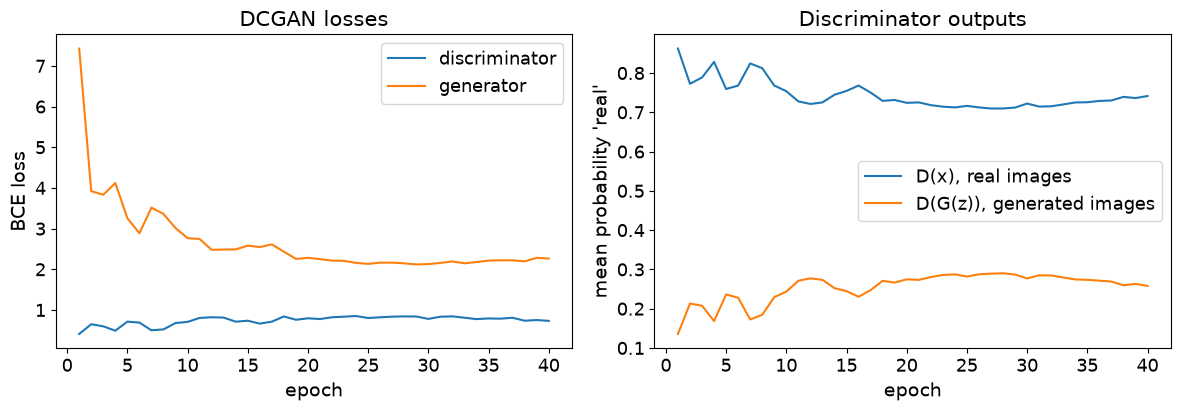

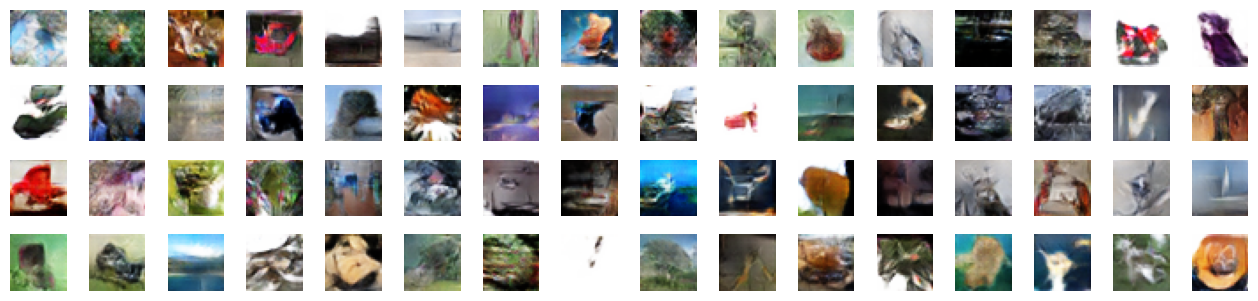

64 generated samples after epoch 40 (fixed noise; 64 = number of fixed noise vectors in train_dcgan)


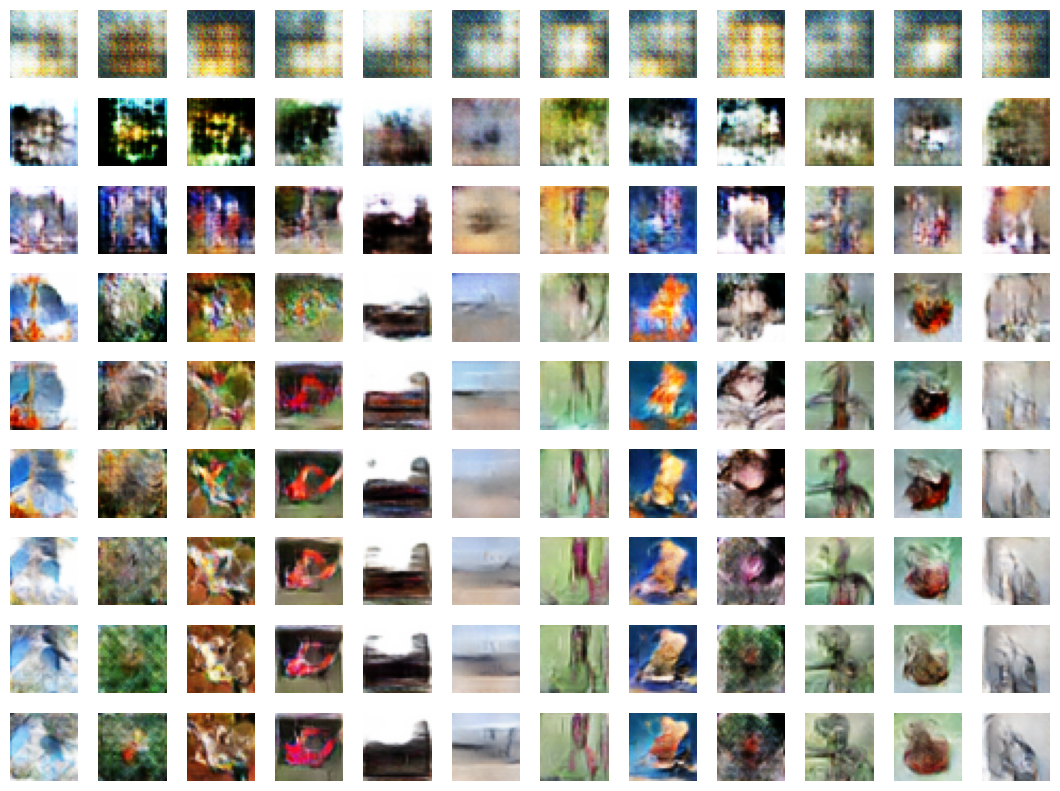

Same 12 noise vectors, one row per snapshot epoch: [1, 5, 10, 15, 20, 25, 30, 35, 40]


In [10]:
# ---------------------------------------------------------------- Parameters
N_PROGRESS = 12   # noise vectors shown per snapshot epoch in the progress grid (one row per snapshot epoch)
# ------------------------------------------------------------------------------
epochs = range(1, len(dcgan_history["loss_d"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(epochs, dcgan_history["loss_d"], label="discriminator")
axes[0].plot(epochs, dcgan_history["loss_g"], label="generator")
axes[0].set(title="DCGAN losses", xlabel="epoch", ylabel="BCE loss"); axes[0].legend()
axes[1].plot(epochs, dcgan_history["d_real"], label="D(x), real images")
axes[1].plot(epochs, dcgan_history["d_fake"], label="D(G(z)), generated images")
axes[1].set(title="Discriminator outputs", xlabel="epoch", ylabel="mean probability 'real'"); axes[1].legend()
plt.tight_layout(); fig.savefig(OUT_DIR / "dcgan_curves.png", dpi=150); plt.show()

last = max(dcgan_snapshots)
show_grid(dcgan_snapshots[last], ncols=16, size=0.8, path=OUT_DIR / "dcgan_samples_final.png")
print(f"64 generated samples after epoch {last} (fixed noise; 64 = number of fixed noise vectors in train_dcgan)")

shown = sorted(dcgan_snapshots)
show_grid(np.concatenate([dcgan_snapshots[e][:N_PROGRESS] for e in shown]), ncols=N_PROGRESS, size=0.9,
          path=OUT_DIR / "dcgan_progress.png")
print("Same 12 noise vectors, one row per snapshot epoch:", shown)

### Are the DCGAN features useful? (linear probe)

Before building the captioner, we check that the discriminator actually learned useful visual features. A **linear probe** freezes a feature extractor and trains only a single linear layer on top to predict the class. If the features are good, a linear layer is enough to classify well.

We compare three feature extractors on the **validation set** (the test set stays untouched until Section 8):

1. **raw pixels** (3,072 numbers per image)
2. **randomly initialised D** (same architecture, no training)
3. **trained DCGAN D** (our model)

D's 512×4×4 output is average-pooled to 512×2×2 = 2,048 features. Features are standardised using training-set statistics.

In [11]:
# ---------------------------------------------------------------- Parameters
PROBE_EPOCHS = 30     # passes over the training features
PROBE_BATCH = 512     # features per training step
PROBE_LR = 1e-3       # AdamW learning rate
PROBE_WD = 5e-4       # AdamW weight decay
EXTRACT_BATCH = 2000  # images per forward pass when extracting features
PROBE_POOL = 2        # D's 4x4 feature map is average-pooled to PROBE_POOL x PROBE_POOL (2 -> 512 x 2 x 2 = 2,048 features per image)
# ------------------------------------------------------------------------------

@torch.no_grad()
def extract_features(fn, x, bs=EXTRACT_BATCH):
    """Apply the feature function `fn` to the images `x` in batches; returns all features flattened to (N, d)."""
    return torch.cat([fn(x[i:i + bs].to(DEVICE)).flatten(1) for i in range(0, len(x), bs)])

def linear_probe(f_train, y_train, f_val, y_val, epochs=PROBE_EPOCHS, bs=PROBE_BATCH, lr=PROBE_LR, wd=PROBE_WD):
    """Train a single 100-way linear layer on frozen, standardised features; returns (fine accuracy, coarse accuracy) on the validation features,
    where coarse accuracy = the predicted fine class mapped to its parent superclass."""
    seed_everything(SEED)
    mean, std = f_train.mean(0), f_train.std(0) + 1e-6
    f_train, f_val = (f_train - mean) / std, (f_val - mean) / std
    y_train, y_val = y_train.to(DEVICE), y_val.to(DEVICE)
    clf = nn.Linear(f_train.size(1), 100).to(DEVICE)
    opt = torch.optim.AdamW(clf.parameters(), lr=lr, weight_decay=wd)
    for _ in range(epochs):
        perm = torch.randperm(len(f_train), device=DEVICE)
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = F.cross_entropy(clf(f_train[b]), y_train[b])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    with torch.no_grad():
        pred = clf(f_val).argmax(1)
    fine_acc = (pred == y_val).float().mean().item()
    coarse_acc = (torch.from_numpy(FINE_TO_COARSE).to(DEVICE)[pred]
                  == torch.from_numpy(FINE_TO_COARSE).to(DEVICE)[y_val]).float().mean().item()
    return fine_acc, coarse_acc

seed_everything(SEED)
D_random = Discriminator(DCGAN_CFG["ndf"]).to(DEVICE).apply(dcgan_init).eval()
D.eval()
# D's 512x4x4 feature map, average-pooled to 512x2x2 = 2,048 numbers per image
pool = lambda net: (lambda x: F.adaptive_avg_pool2d(net.features(x), PROBE_POOL))
extractors = {
    "raw pixels": lambda x: x,
    "random D (untrained)": pool(D_random),
    "DCGAN D (trained)": pool(D),
}

probe_results = {}
for name, fn in extractors.items():
    f_tr, f_va = extract_features(fn, X["train"]), extract_features(fn, X["val"])
    probe_results[name] = linear_probe(f_tr, Y_FINE["train"], f_va, Y_FINE["val"])
    print(f"{name:22s} | {f_tr.size(1):5d} features | val fine acc {probe_results[name][0]:.1%} | val coarse acc {probe_results[name][1]:.1%}")
print("(chance level: fine 1.0%, coarse 5.0%)")

raw pixels             |  3072 features | val fine acc 14.5% | val coarse acc 25.2%


random D (untrained)   |  2048 features | val fine acc 25.1% | val coarse acc 36.3%


DCGAN D (trained)      |  2048 features | val fine acc 40.9% | val coarse acc 53.3%
(chance level: fine 1.0%, coarse 5.0%)


### Section 3 findings summary

* The DCGAN is trained only on the 36,000 training images, without labels.
* The linear probe shows how much the discriminator's features help compared with raw pixels and an untrained network of the same shape.
* In Section 5 we copy `D.features` into the captioner's image encoder and train it together with a Transformer decoder. Section 7 compares this against a randomly initialised encoder and a frozen DCGAN encoder to measure what the DCGAN contributes to caption quality.

## 4. Stable Diffusion: synthetic training images

**Role of Stable Diffusion in the pipeline.** The captioner only sees 36,000 training images (360 per class). Stable Diffusion is an open-source text-to-image model that can produce more images of every class, so we use it as a *data generator*: for each of the 100 fine classes we write a text prompt that contains the class name, generate images, shrink them to 32×32, and give them the same label-based captions as real images (Section 2). The prompt uses the class label only, so the caption of a synthetic image is known without looking at it.

Rules we keep:

* Synthetic images are used **for training only**. Validation and test sets contain real CIFAR-100 images only.
* Whether they help is **measured**, not assumed: Section 7 trains the same captioner with and without them.

**Model.** `stabilityai/sd-turbo` (a distilled Stable Diffusion 2.1 that needs only 1–4 sampling steps) so that thousands of images take minutes instead of hours; we use 2 steps. It is an existing open-source model, which the assignment allows. A few class names are ambiguous as single words (`ray`, `seal`, `can`, `tank`, ...), so their prompts carry a short hint; the *caption* keeps the plain label.

Generation is cached in `data/sd_cache/` and merged into `data/sd_synthetic.npz`; delete these to regenerate. Set `GENERATE_SD = False` to never run Stable Diffusion: an existing `data/sd_synthetic.npz` is still loaded and used, and the SD experiments (D and E in Section 7) are skipped only if that file does not exist.

In [12]:
# Generate (or load) the Stable Diffusion training images; generation is skipped when data/sd_synthetic.npz already exists.
# ---------------------------------------------------------------- Parameters
GENERATE_SD = True          # False: never run Stable Diffusion (use data/sd_synthetic.npz if it exists)
SD_MODEL = "stabilityai/sd-turbo"   # Hugging Face id of the Stable Diffusion model
SD_PER_CLASS = 100          # synthetic images per fine class (100 classes -> 10,000 images)
SD_STEPS = 2                # denoising steps: SD-Turbo is distilled for 1-4 steps and is used without classifier-free guidance
SD_BATCH = 25               # prompts per GPU call
SD_GUIDANCE = 0.0           # classifier-free guidance scale; SD-Turbo is trained without guidance, so keep 0
SD_SIZE = 512               # generation size in pixels (SD-Turbo's native size); every image is then shrunk to 32x32
SD_PREVIEW = 128            # side in pixels of the preview thumbnail saved for the first image of each class
SD_CACHE = DATA_DIR / "sd_cache"             # one file per class, so an interrupted run resumes where it stopped
sd_path = DATA_DIR / "sd_synthetic.npz"      # merged result: images (N, 32, 32, 3) and their fine labels
# ------------------------------------------------------------------------------

# Short hints for class names that are ambiguous as a single word (prompt only; captions keep the plain label).
PROMPT_HINT = {
    "ray": "a manta ray fish swimming underwater", "seal": "a seal animal", "plain": "a wide flat grassland plain",
    "sea": "the open sea with waves", "cloud": "clouds in the sky", "can": "a metal tin can", "tank": "an army battle tank",
    "mouse": "a small mouse animal", "bowl": "an empty bowl", "keyboard": "a computer keyboard", "couch": "a sofa couch",
    "plate": "a dinner plate", "cattle": "cattle cows in a field", "orange": "an orange fruit", "worm": "an earthworm",
    "streetcar": "a streetcar tram", "shrew": "a shrew small mammal", "lobster": "a lobster animal", "crab": "a crab animal",
    "flatfish": "a flatfish on the sea floor", "forest": "a forest with many trees", "road": "a road", "table": "a wooden table",
}
# prompt wordings, cycled over the SD_PER_CLASS images of a class to get varied images
PROMPT_STYLES = [
    "a photo of {x}",
    "a close-up photo of {x}",
    "a photo of {x}, centered, simple background",
    "a low-resolution photograph of {x}",
    "{x} in its natural setting, photo",
]

def sd_prompts(fine_id):
    """The SD_PER_CLASS text prompts for one fine class: its (hinted) name inserted into each of the PROMPT_STYLES in turn."""
    x = PROMPT_HINT.get(FINE_PHRASE[fine_id], noun_phrase(FINE_PHRASE[fine_id]))
    return [PROMPT_STYLES[j % len(PROMPT_STYLES)].format(x=x) for j in range(SD_PER_CLASS)]

def generate_sd_images():
    """Generate SD_PER_CLASS images per class with Stable Diffusion, shrink them to 32x32, cache them per class and merge them into sd_path."""
    assert DEVICE.type == "cuda", "Stable Diffusion needs a GPU"
    try:
        import diffusers
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers", "transformers", "accelerate"], check=True)
    from diffusers import AutoPipelineForText2Image
    from PIL import Image

    SD_CACHE.mkdir(parents=True, exist_ok=True)
    pipe = AutoPipelineForText2Image.from_pretrained(SD_MODEL, torch_dtype=torch.float16, variant="fp16").to(DEVICE)
    pipe.set_progress_bar_config(disable=True)
    t0 = time.time()
    for c in range(len(FINE_NAMES)):
        f = SD_CACHE / f"{c:03d}.npy"
        if f.exists():
            continue
        prompts, out = sd_prompts(c), []
        for b in range(0, len(prompts), SD_BATCH):
            # a different but reproducible seed for every (class c, batch start b), derived from SEED
            g = torch.Generator(DEVICE).manual_seed(SEED * 100003 + c * 1000 + b)
            ims = pipe(prompts[b:b + SD_BATCH], num_inference_steps=SD_STEPS, guidance_scale=SD_GUIDANCE,
                       height=SD_SIZE, width=SD_SIZE, generator=g).images
            if b == 0:
                ims[0].resize((SD_PREVIEW, SD_PREVIEW), Image.BOX).save(SD_CACHE / f"preview_{c:03d}.png")
            out += [np.asarray(im.convert("RGB").resize((32, 32), Image.BOX)) for im in ims]   # area average = anti-aliased downsample
        np.save(f, np.stack(out))
        print(f"class {c + 1:3d}/{len(FINE_NAMES)} {FINE_NAMES[c]:15s} | {time.time() - t0:6.0f}s", flush=True)
    del pipe
    torch.cuda.empty_cache()
    imgs = [np.load(SD_CACHE / f"{c:03d}.npy") for c in range(len(FINE_NAMES))]
    assert all(len(a) == SD_PER_CLASS for a in imgs), "cache holds a different SD_PER_CLASS; delete data/sd_cache"
    np.savez(sd_path, images=np.concatenate(imgs), fine=np.repeat(np.arange(len(FINE_NAMES)), SD_PER_CLASS))

if not sd_path.exists() and GENERATE_SD:
    generate_sd_images()
if sd_path.exists():
    _sd = np.load(sd_path)
    SD_IMAGES, SD_FINE = _sd["images"], _sd["fine"]
    print(f"Synthetic images: {SD_IMAGES.shape} {SD_IMAGES.dtype}, {len(np.unique(SD_FINE))} classes, "
          f"{np.bincount(SD_FINE).min()}-{np.bincount(SD_FINE).max()} per class")
else:
    SD_IMAGES = SD_FINE = None
    print("No synthetic images (GENERATE_SD = False): the Stable Diffusion experiments will be skipped.")


Synthetic images: (10000, 32, 32, 3) uint8, 100 classes, 100-100 per class


X_SD (10000, 3, 32, 32), CAP_SD (10000, 5, 12)  (+28% on top of the 36,000 real training images)


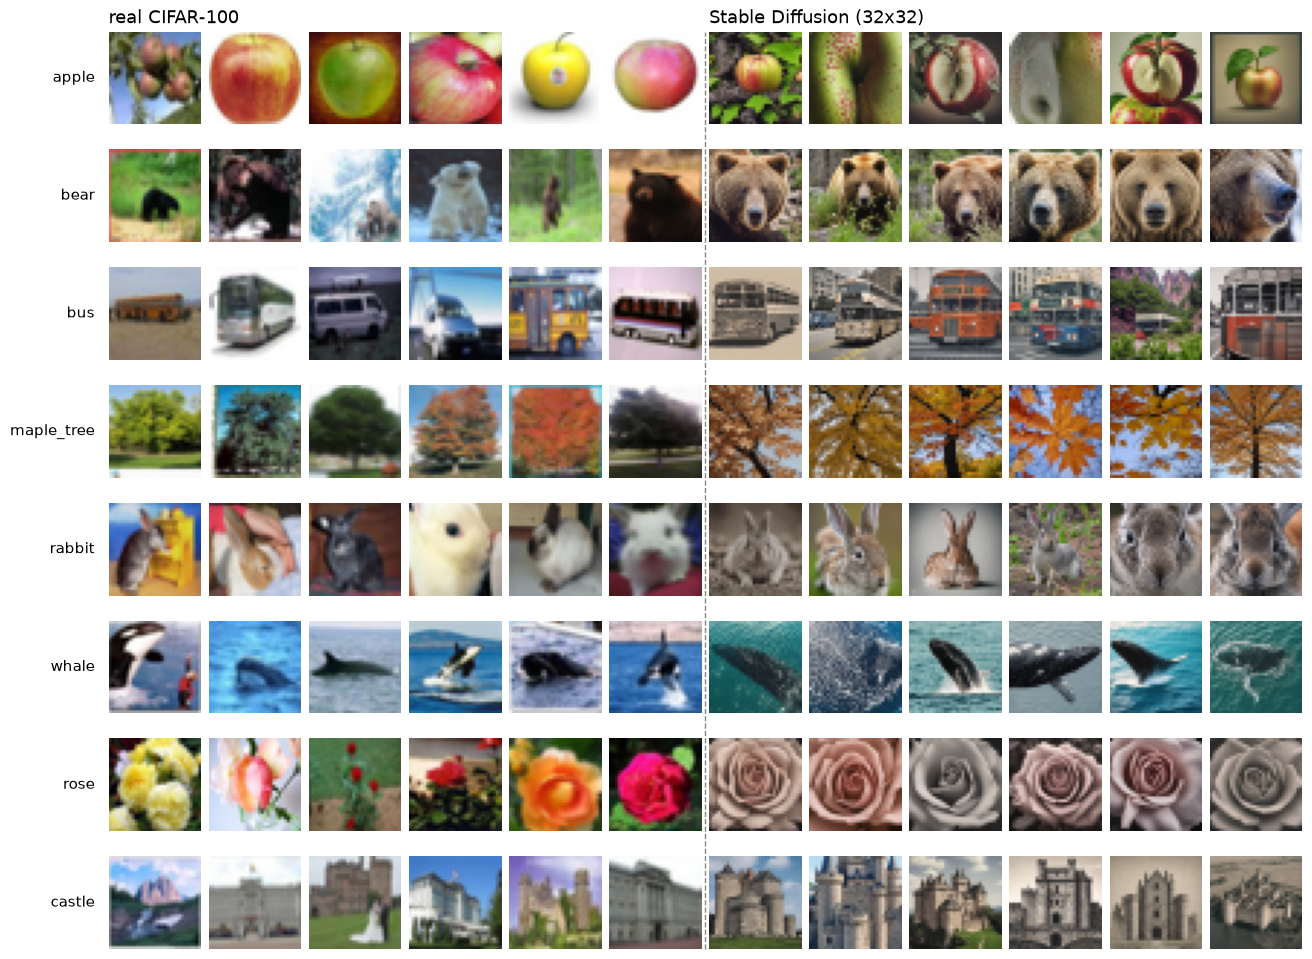

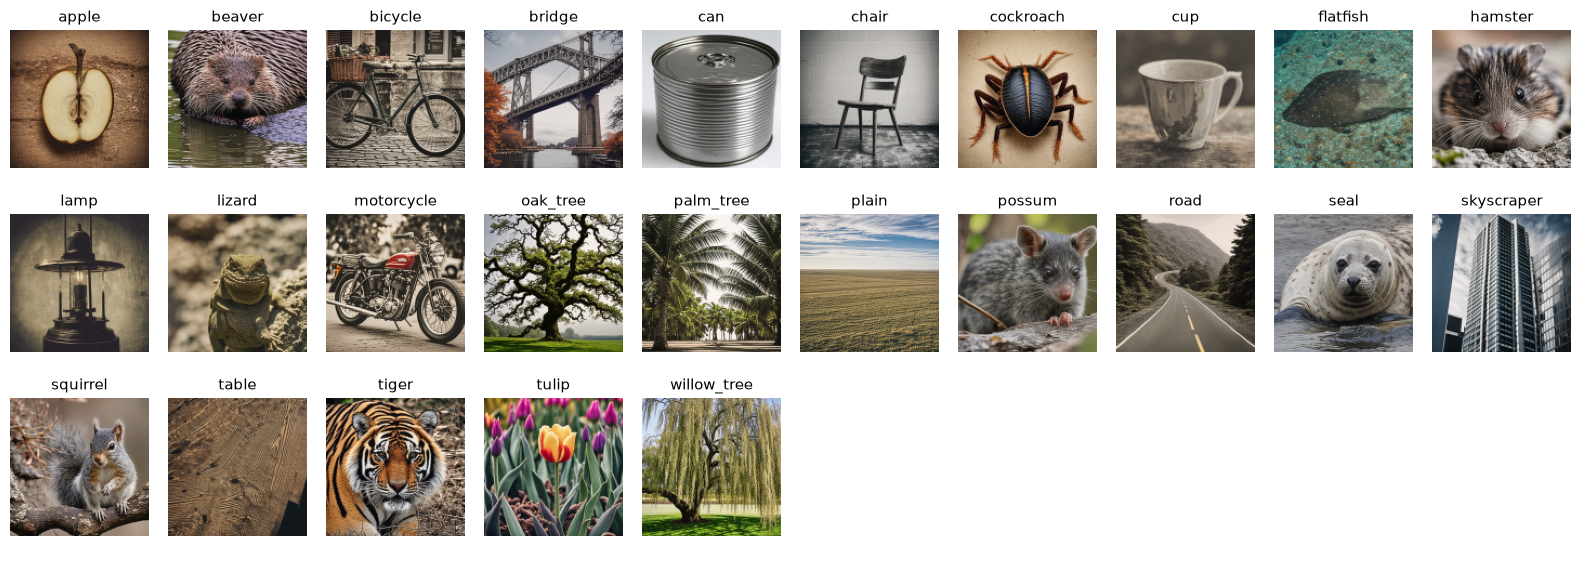

Stable Diffusion outputs at 128x128 (the 512x512 originals reduced 4x, before the 32x32 downsampling): first image of every 4th class


In [13]:
# Turn the synthetic images into training tensors, give them label captions, and compare them with real images.
# ---------------------------------------------------------------- Parameters
SHOW_CLASSES = ["apple", "bear", "bus", "maple_tree", "rabbit", "whale", "rose", "castle"]   # classes shown side by side
N_SHOW = 6   # real images and synthetic images shown per class (the grid has 2 * N_SHOW columns)
# ------------------------------------------------------------------------------
if SD_IMAGES is not None:
    X_SD = to_tensor(SD_IMAGES)   # same [-1, 1] scaling as the real images
    # CAP_SD[i, k] = ids of reference caption k of synthetic image i (from its class label, like real images)
    CAP_SD = torch.tensor([[vocab.encode(c, MAX_LEN) for c in make_captions(f)] for f in SD_FINE])
    print(f"X_SD {tuple(X_SD.shape)}, CAP_SD {tuple(CAP_SD.shape)}  (+{len(X_SD) / len(X['train']):.0%} on top of the 36,000 real training images)")

    # real vs synthetic, same classes, same 32x32 resolution
    names = SHOW_CLASSES
    rng = np.random.default_rng(1)
    fig, axes = plt.subplots(len(names), 2 * N_SHOW, figsize=(2 * N_SHOW * 1.15, len(names) * 1.25))
    for r, name in enumerate(names):
        c = FINE_NAMES.index(name)
        real = rng.choice(SPLITS["train"][fine_labels[SPLITS["train"]] == c], N_SHOW, replace=False)
        syn = rng.choice(np.flatnonzero(SD_FINE == c), N_SHOW, replace=False)
        for k, im in enumerate(list(images[real]) + list(SD_IMAGES[syn])):
            axes[r, k].imshow(im); axes[r, k].axis("off")
        axes[r, 0].text(-0.15, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=PLOT_FONT - 2)
    # the first N_SHOW columns are real images, the last N_SHOW are Stable Diffusion images: title each half and draw a dashed line between them
    axes[0, 0].set_title("real CIFAR-100", fontsize=PLOT_FONT, loc="left"); axes[0, N_SHOW].set_title("Stable Diffusion (32x32)", fontsize=PLOT_FONT, loc="left")
    fig.subplots_adjust(left=0.13, right=0.995, top=0.94, bottom=0.01, wspace=0.08, hspace=0.12)   # fixed margins: the row names sit outside the grid
    x_mid = (axes[0, N_SHOW - 1].get_position().x1 + axes[0, N_SHOW].get_position().x0) / 2
    fig.add_artist(plt.Line2D([x_mid, x_mid], [axes[-1, 0].get_position().y0, axes[0, 0].get_position().y1], color="#888780", lw=1, ls="--"))
    fig.savefig(OUT_DIR / "sd_vs_real.png", dpi=150, bbox_inches="tight"); plt.show()

    previews = [SD_CACHE / f"preview_{c:03d}.png" for c in range(0, 100, 4)]
    if all(p.exists() for p in previews):
        from PIL import Image
        show_grid([np.asarray(Image.open(p)) for p in previews], [FINE_NAMES[c] for c in range(0, 100, 4)],
                  ncols=10, size=1.6, path=OUT_DIR / "sd_samples_fullres.png")
        print("Stable Diffusion outputs at 128x128 (the 512x512 originals reduced 4x, before the 32x32 downsampling): first image of every 4th class")


## 5. Captioning model

```
image (3×32×32) ──► CNN encoder ──► 512×4×4 ──► 16 visual tokens ──► Linear + position embedding ──► memory (16×d)
                                                                                                    │ cross-attention
<bos> w1 w2 ... ──► token embedding + position embedding ──► [masked self-attention → cross-attention → MLP] × L ──► next-word logits
```

* **Encoder.** The same three strided convolutions as the DCGAN discriminator (`Discriminator.features`). Its weights are either copied from the trained DCGAN or randomly initialised (Section 7 compares both). Each of the 4×4 = 16 grid cells becomes one visual token.
* **Decoder.** A Transformer decoder with **hand-written multi-head attention** (no `nn.MultiheadAttention`, no `nn.Transformer`): pre-LayerNorm blocks with causal masked self-attention over the words so far, cross-attention to the 16 visual tokens, and a GELU MLP. Output embeddings are tied to the input word embeddings.
* **Training objective.** Teacher forcing: given `<bos> w1 ... wn` and the image, predict `w1 ... wn <eos>` (inputs = the padded caption without its last token, targets = the same caption shifted left by one; padding is ignored) with cross-entropy (padding ignored).
* **Decoding.** Greedy decoding and beam search, both implemented below.

In [14]:
# ---------------------------------------------------------------- Parameters (model size and training; used by Sections 6-8)
CAP_CFG = dict(
    d_model=256,        # width of the visual tokens and word embeddings
    n_heads=8,          # attention heads (d_model must be divisible by n_heads)
    n_layers=3,         # decoder blocks
    d_ff=1024,          # hidden size of the MLP in every decoder block
    dropout=0.1,        # dropout probability
    epochs=30,          # passes over the training set (plus the synthetic images when they are used)
    batch_size=256,     # images per training step
    lr=3e-4,            # peak AdamW learning rate (linear warm-up, then cosine decay to 0)
    weight_decay=0.01,  # AdamW weight decay
    warmup_frac=0.05,   # share of all training steps used for the learning-rate warm-up
    grad_clip=1.0,      # maximum gradient norm
)
ENCODERS = {   # encoder variant -> (initialise from the trained DCGAN?, keep frozen?)
    "random": (False, False),   # random weights, trained
    "dcgan": (True, False),     # DCGAN weights, fine-tuned
    "frozen": (True, True),     # DCGAN weights, not trained
}
# NOTE: with saved checkpoints (checkpoints/captioners/*.pt, TRAIN_CAPTIONERS = False) the runs are only loaded, so the training entries
# (epochs ... grad_clip) are not used; the model-size entries must match the checkpoints. Delete them or set TRAIN_CAPTIONERS = True to retrain.
# ------------------------------------------------------------------------------

class MultiHeadAttention(nn.Module):
    """Scaled dot-product attention with several heads. `mask` is True where attention is allowed."""
    def __init__(self, d_model, n_heads, dropout=0.0):
        """d_model: feature size; n_heads: number of attention heads; dropout: applied to the attention weights."""
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dk = n_heads, d_model // n_heads
        self.q, self.k, self.v, self.o = (nn.Linear(d_model, d_model) for _ in range(4))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, mask=None):
        """Queries come from x (B, Tq, d), keys and values from memory (B, Tk, d); returns (output (B, Tq, d), attention weights (B, h, Tq, Tk))."""
        B, Tq, _ = x.shape
        Tk = memory.size(1)
        q = self.q(x).view(B, Tq, self.h, self.dk).transpose(1, 2)        # (B, h, Tq, dk)
        k = self.k(memory).view(B, Tk, self.h, self.dk).transpose(1, 2)   # (B, h, Tk, dk)
        v = self.v(memory).view(B, Tk, self.h, self.dk).transpose(1, 2)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dk)             # (B, h, Tq, Tk)
        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))
        attn = scores.softmax(-1)
        out = (self.drop(attn) @ v).transpose(1, 2).reshape(B, Tq, -1)
        return self.o(out), attn


class DecoderLayer(nn.Module):
    """One decoder block (pre-LayerNorm, each part with a residual connection): masked self-attention over the words,
    cross-attention to the image tokens, then a two-layer MLP."""
    def __init__(self, d_model, n_heads, d_ff, dropout):
        """d_ff: hidden size of the MLP; d_model and n_heads as in MultiHeadAttention; dropout: probability on the attention weights, on every residual branch and inside the MLP."""
        super().__init__()
        self.ln1, self.ln2, self.ln3 = (nn.LayerNorm(d_model) for _ in range(3))
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)
        self.cross_weights = None   # last cross-attention map (B, h, Tq, 16), kept for visualisation

    def forward(self, x, memory, causal):
        """x: word states (B, T, d); memory: image tokens (B, 16, d); causal: mask that hides later words. Returns (B, T, d).
        Side effect: stores the cross-attention map in self.cross_weights (used for the attention figure in Section 8)."""
        h = self.ln1(x)
        x = x + self.drop(self.self_attn(h, h, causal)[0])
        out, w = self.cross_attn(self.ln2(x), memory)
        self.cross_weights = w.detach()
        x = x + self.drop(out)
        return x + self.drop(self.ff(self.ln3(x)))


class ImageEncoder(nn.Module):
    """CNN image encoder: the DCGAN-discriminator layers turn a 32x32 image into a 4x4 grid; every cell becomes one visual token.
    `pretrained_features` copies the DCGAN weights into the CNN; `freeze=True` keeps them fixed."""
    N_TOKENS = 16   # 4x4 grid

    def __init__(self, d_model, ndf, pretrained_features=None, freeze=False):
        """d_model: token size; ndf: CNN width (must equal the DCGAN's); pretrained_features: DCGAN `features` to copy, or None for random weights; freeze: keep the CNN fixed."""
        super().__init__()
        self.cnn = Discriminator(ndf).features            # same layers as the DCGAN discriminator
        if pretrained_features is not None:
            self.cnn.load_state_dict(pretrained_features.state_dict())
        self.freeze = freeze
        if freeze:
            self.cnn.requires_grad_(False)
        self.proj = nn.Linear(ndf * 4, d_model)
        self.pos = nn.Parameter(torch.randn(1, self.N_TOKENS, d_model) * 0.02)
        self.norm = nn.LayerNorm(d_model)

    def train(self, mode=True):
        """Switch train/eval mode; a frozen CNN always stays in eval mode so its BatchNorm statistics do not change."""
        super().train(mode)
        if self.freeze:
            self.cnn.eval()   # a frozen encoder also keeps its BatchNorm statistics fixed
        return self

    def forward(self, x):
        """Images (B, 3, 32, 32) -> visual tokens (B, 16, d_model)."""
        f = self.cnn(x)                                   # (B, 512, 4, 4)
        tokens = f.flatten(2).transpose(1, 2)             # (B, 16, 512): one token per grid cell
        return self.norm(self.proj(tokens) + self.pos)


class Captioner(nn.Module):
    """Image captioner = ImageEncoder + Transformer decoder (output layer tied to the word embeddings).
    forward() is the teacher-forced pass used for training; generate() writes captions for new images."""
    def __init__(self, vocab_size, max_len, d_model=256, n_heads=8, n_layers=3, d_ff=1024, dropout=0.1,
                 ndf=128, pretrained_features=None, freeze_encoder=False):
        """Sizes as in CAP_CFG; max_len: longest caption incl. <bos>/<eos>; ndf, pretrained_features, freeze_encoder: passed to the ImageEncoder."""
        super().__init__()
        self.d_model = d_model
        self.encoder = ImageEncoder(d_model, ndf, pretrained_features, freeze_encoder)
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        nn.init.normal_(self.tok_emb.weight, std=d_model ** -0.5)
        self.pos_emb = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)
        self.layers = nn.ModuleList(DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.ln_f = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.register_buffer("causal", torch.tril(torch.ones(max_len, max_len, dtype=torch.bool))[None, None], persistent=False)

    def encode(self, x):
        """Images -> visual tokens (B, 16, d_model)."""
        return self.encoder(x)

    def decode(self, ids, memory):
        """Word ids (B, T) + visual tokens (B, 16, d) -> next-word logits (B, T, vocab) at every position."""
        T = ids.size(1)
        h = self.drop(self.tok_emb(ids) * math.sqrt(self.d_model) + self.pos_emb[:, :T])
        for layer in self.layers:
            h = layer(h, memory, self.causal[:, :, :T, :T])
        return self.ln_f(h) @ self.tok_emb.weight.T       # tied output embedding -> (B, T, vocab)

    def forward(self, x, ids_in):
        """Teacher-forced pass: images and the caption without its last token (<bos> w1 ... wn <eos> <pad> ...) -> logits (B, T, vocab) for the next word at each position."""
        return self.decode(ids_in, self.encode(x))

    @torch.no_grad()
    def generate(self, x, beam=1, max_len=None):
        """Write captions for a batch of images by greedy (beam=1) or beam-search decoding; returns token ids (B, <= max_len) starting with <bos>."""
        max_len = max_len or MAX_LEN
        B = x.size(0)
        mem = self.encode(x).repeat_interleave(beam, 0)
        seqs = torch.full((B * beam, 1), vocab.bos_id, device=x.device)
        scores = torch.zeros(B, beam, device=x.device)
        scores[:, 1:] = float("-inf")                     # all beams start identical: let only the first one expand
        done = torch.zeros(B * beam, dtype=torch.bool, device=x.device)
        V = len(vocab)
        for _ in range(max_len - 1):   # one new word per step
            logp = self.decode(seqs, mem)[:, -1].log_softmax(-1)               # (B*beam, V)
            logp[done] = float("-inf")
            logp[done, vocab.pad_id] = 0.0                                     # finished beams only emit <pad> at no cost
            cand = (scores.view(-1, 1) + logp).view(B, beam * V)
            scores, top = cand.topk(beam, dim=-1)                              # best `beam` of the beam*V continuations
            src = (torch.arange(B, device=x.device)[:, None] * beam + top // V).view(-1)
            tok = (top % V).view(-1, 1)
            seqs = torch.cat([seqs[src], tok], 1)
            done = done[src] | (tok.view(-1) == vocab.eos_id)
            if done.all():
                break
        best = scores.argmax(1)
        return seqs.view(B, beam, -1)[torch.arange(B, device=x.device), best]


def build_captioner(encoder):
    """Create a Captioner with the sizes in CAP_CFG (the CNN width ndf comes from DCGAN_CFG) and the encoder variant `encoder` ("random", "dcgan" or "frozen", see ENCODERS)."""
    from_dcgan, frozen = ENCODERS[encoder]
    return Captioner(len(vocab), MAX_LEN, **{k: CAP_CFG[k] for k in ("d_model", "n_heads", "n_layers", "d_ff", "dropout")},
                     ndf=DCGAN_CFG["ndf"], pretrained_features=D.features if from_dcgan else None,
                     freeze_encoder=frozen).to(DEVICE)

# ---- unit checks of the hand-written parts
seed_everything(SEED)
m = build_captioner("dcgan").eval()
xb = X["val"][:4].to(DEVICE)
ids = Y_CAPS["val"][:4, 0].to(DEVICE)
logits = m(xb, ids[:, :-1])
print("logits", tuple(logits.shape), "= (batch, caption length - 1, vocab size)")

att = m.layers[0].self_attn
h = torch.randn(2, 5, CAP_CFG["d_model"], device=DEVICE)
ours = att(h, h, m.causal[:, :, :5, :5])[0]
split = lambda t: t.view(2, 5, att.h, att.dk).transpose(1, 2)   # (B, T, d) -> (B, heads, T, dk): the head split of MultiHeadAttention.forward
ref = F.scaled_dot_product_attention(split(att.q(h)), split(att.k(h)), split(att.v(h)), is_causal=True)
ref = att.o(ref.transpose(1, 2).reshape(2, 5, -1))
print("attention matches F.scaled_dot_product_attention:", torch.allclose(ours, ref, atol=1e-5))

other = ids[:, :-1].clone(); other[:, 4:] = torch.randint(4, len(vocab), other[:, 4:].shape, device=DEVICE)
print("causal mask (changing later words leaves earlier logits unchanged):", torch.allclose(logits[:, :4], m(xb, other)[:, :4], atol=1e-5))

g1 = m.generate(xb, beam=1)
print("beam=1 equals greedy by construction; beam=3 output shape:", tuple(m.generate(xb, beam=3).shape))
for name in ENCODERS:
    mm = build_captioner(name)
    print(f"{name:7s} encoder | parameters: {count_params(mm):,} total, {sum(p.numel() for p in mm.parameters() if p.requires_grad):,} trainable")
del m, mm


logits (4, 11, 151) = (batch, caption length - 1, vocab size)
attention matches F.scaled_dot_product_attention: True
causal mask (changing later words leaves earlier logits unchanged): True
beam=1 equals greedy by construction; beam=3 output shape: (4, 12)
random  encoder | parameters: 5,967,616 total, 5,967,616 trainable


dcgan   encoder | parameters: 5,967,616 total, 5,967,616 trainable
frozen  encoder | parameters: 5,967,616 total, 3,338,496 trainable


## 6. Training, decoding and evaluation metrics

### Metrics

For each generated caption we compare against the **5 reference captions** of its image:

* **BLEU-1…4** and **CIDEr-D**, the standard captioning metrics, implemented here from scratch (BLEU as corpus BLEU with the closest-reference-length brevity penalty; CIDEr-D with TF-IDF weighted n-grams, document frequencies from the reference sets, Gaussian length penalty σ = 6, clipping, ×10). Both were checked against `nltk` and `pycocoevalcap` outside this notebook.
* **Fine accuracy:** does the caption name the correct fine class? (parsed from the caption text)
* **Coarse accuracy:** is the *parent category of the named class* the correct coarse class?
* **Category consistency:** among captions that state a category ("... from the X category"), how often is the stated category the parent of the class the caption itself names? This checks that the decoder is coherent, independent of whether it recognised the object.
* **Exact match:** how often is the generated caption identical to one of the 5 references?

BLEU and CIDEr reward any of the five templates, so with label-based captions they mostly reflect whether the right class was named; fine accuracy is the cleaner measure of recognition.

In [15]:
from collections import defaultdict

# ---------------------------------------------------------------- Parameters
BLEU_MAX_N = 4       # BLEU-1 ... BLEU-4
CIDER_N = 4          # longest n-gram used by CIDEr-D
CIDER_SIGMA = 6.0    # width of CIDEr-D's Gaussian length penalty
EVAL_BATCH = 1000    # images per forward pass when generating captions
# ------------------------------------------------------------------------------

def ngrams(tokens, n):
    """Counter of the n-grams (tuples of n consecutive tokens) of a token list."""
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def corpus_bleu(hyps, refs_list, max_n=BLEU_MAX_N):
    """Corpus BLEU-1..max_n of generated captions against several references per image (clipped n-gram precision, closest-reference-length
    brevity penalty); returns {"bleu1": ..., "bleu2": ...}."""
    clipped, total = [0] * max_n, [0] * max_n
    hyp_len = ref_len = 0
    for hyp, refs in zip(hyps, refs_list):
        h, rs = tokenize(hyp), [tokenize(r) for r in refs]
        hyp_len += len(h)
        ref_len += min((abs(len(r) - len(h)), len(r)) for r in rs)[1]   # closest reference length (ties: shorter)
        for n in range(1, max_n + 1):
            best = Counter()
            for r in rs:
                for g, c in ngrams(r, n).items():
                    best[g] = max(best[g], c)
            clipped[n - 1] += sum(min(c, best[g]) for g, c in ngrams(h, n).items())
            total[n - 1] += max(len(h) - n + 1, 0)
    bp = 1.0 if hyp_len > ref_len else math.exp(1 - ref_len / max(hyp_len, 1))
    out = {}
    for k in range(1, max_n + 1):
        if min(clipped[:k]) == 0:
            out[f"bleu{k}"] = 0.0
        else:
            out[f"bleu{k}"] = bp * math.exp(sum(math.log(clipped[j] / total[j]) for j in range(k)) / k)
    return out

def cider_d(hyps, refs_list, n=CIDER_N, sigma=CIDER_SIGMA):
    """CIDEr-D score (mean over images, x10): TF-IDF weighted n-gram cosine similarity between a caption and each of its references,
    with a Gaussian penalty on the length difference."""
    # document frequency: in how many images' reference sets does each n-gram occur
    df = Counter()
    for refs in refs_list:
        seen = set()
        for r in refs:
            t = tokenize(r)
            for k in range(1, n + 1):
                seen.update(ngrams(t, k))
        df.update(seen)
    log_N = math.log(len(refs_list))

    def vec(tokens):
        """TF-IDF vector per n-gram order, their norms, and the length of a token list."""
        v, norm = [defaultdict(float) for _ in range(n)], [0.0] * n
        for k in range(1, n + 1):
            for g, c in ngrams(tokens, k).items():
                v[k - 1][g] = c * (log_N - math.log(max(1.0, df[g])))
                norm[k - 1] += v[k - 1][g] ** 2
        return v, [math.sqrt(x) for x in norm], len(tokens)

    def sim(a, b):
        """Length-penalised cosine similarity per n-gram order between two (vectors, norms, length) triples."""
        (va, na, la), (vb, nb, lb) = a, b
        val = np.zeros(n)
        for k in range(n):
            for g, x in va[k].items():
                val[k] += min(x, vb[k].get(g, 0.0)) * vb[k].get(g, 0.0)
            if na[k] != 0 and nb[k] != 0:
                val[k] /= na[k] * nb[k]
            val[k] *= math.exp(-((la - lb) ** 2) / (2 * sigma ** 2))
        return val

    scores = []
    for hyp, refs in zip(hyps, refs_list):
        h = vec(tokenize(hyp))
        scores.append(np.mean([sim(h, vec(tokenize(r))) for r in refs], axis=0).mean() * 10.0)
    return float(np.mean(scores))

# ---- parse the class names a caption mentions: FINE_TOK maps a token tuple -> fine class id; COARSE_TOK maps a token tuple -> SET of coarse
# ---- class ids (the two vehicle superclasses share the phrase "vehicles")
FINE_TOK = {tuple(tokenize(p)): i for i, p in enumerate(FINE_PHRASE)}
COARSE_TOK = defaultdict(set)
for ci, p in enumerate(COARSE_PHRASE):
    COARSE_TOK[tuple(tokenize(p))].add(ci)
_MAXL = max(len(k) for k in list(FINE_TOK) + list(COARSE_TOK))   # tokens in the longest class phrase (window size of find_phrase)

def find_phrase(tokens, table, start=0):
    """First (longest-match) phrase of `table` in `tokens`; returns (value, end index) or (None, start)."""
    for i in range(start, len(tokens)):
        for L in range(_MAXL, 0, -1):
            key = tuple(tokens[i:i + L])
            if key in table:
                return table[key], i + L
    return None, start

def parse_caption(cap):
    """Class names a caption mentions: (fine class id or -1 if none, set of coarse class ids or None if no category is stated)."""
    toks = tokenize(cap)
    fine, end = find_phrase(toks, FINE_TOK)
    coarse, _ = find_phrase(toks, COARSE_TOK, end if fine is not None else 0)
    return (-1 if fine is None else fine), coarse           # coarse: set of coarse ids, or None

@torch.no_grad()
def predict_captions(model, x, beam=1, bs=EVAL_BATCH):
    """Caption every image of `x` (beam=1: greedy, otherwise beam search) in batches of `bs`; returns a list of strings."""
    model.eval()
    out = []
    for i in range(0, len(x), bs):
        out += [vocab.decode(r) for r in model.generate(x[i:i + bs].to(DEVICE), beam=beam).cpu()]
    return out

def score_captions(hyps, idx):
    """Score captions `hyps` against the 5 references of the images `idx` (indices into the full 60,000-image pool, e.g. SPLITS["val"]);
    returns ({fine_acc, coarse_acc, category_consistency, exact_match, bleu1-4, cider}, predicted fine class id per image, -1 = none named)."""
    refs = [CAPTIONS[i] for i in idx]
    true_fine, true_coarse = fine_labels[idx], coarse_labels[idx]
    parsed = [parse_caption(h) for h in hyps]
    pred_fine = np.array([p[0] for p in parsed])
    ok_fine = pred_fine == true_fine
    ok_coarse = np.array([f >= 0 and FINE_TO_COARSE[f] == t for f, t in zip(pred_fine, true_coarse)])
    stated = [(f, c) for f, c in parsed if c is not None and f >= 0]
    res = dict(fine_acc=ok_fine.mean(), coarse_acc=ok_coarse.mean(),
               category_consistency=np.mean([FINE_TO_COARSE[f] in c for f, c in stated]) if stated else float("nan"),
               exact_match=np.mean([h in r for h, r in zip(hyps, refs)]),
               **corpus_bleu(hyps, refs), cider=cider_d(hyps, refs))
    return {k: float(v) for k, v in res.items()}, pred_fine

def evaluate(model, split, beam=1):
    """Caption all images of a split ("val" or "test") and score them; returns (metrics, captions, predicted fine class ids)."""
    hyps = predict_captions(model, X[split], beam)
    res, pred_fine = score_captions(hyps, SPLITS[split])
    return res, hyps, pred_fine

# ---- sanity checks of the metrics on 2000 validation images, using template [2] ("... from the X category", the one that states a category):
# ---- a genuine reference caption must give accuracies, exact match and BLEU of 1.0 (CIDEr about 5: it equals only one of the 5 references);
# ---- the caption of another image must score near 0 on accuracy and CIDEr
idx = SPLITS["val"][:2000]
perfect = [CAPTIONS[i][2] for i in idx]
shifted = [CAPTIONS[idx[(j + 1) % len(idx)]][2] for j in range(len(idx))]
for name, hyps in [("a reference caption", perfect), ("caption of another image", shifted)]:
    r, _ = score_captions(hyps, idx)
    print(f"{name:26s} | " + " | ".join(f"{k} {v:.3f}" for k, v in r.items()))


a reference caption        | fine_acc 1.000 | coarse_acc 1.000 | category_consistency 1.000 | exact_match 1.000 | bleu1 1.000 | bleu2 1.000 | bleu3 1.000 | bleu4 1.000 | cider 5.007


caption of another image   | fine_acc 0.009 | coarse_acc 0.048 | category_consistency 1.000 | exact_match 0.009 | bleu1 0.588 | bleu2 0.343 | bleu3 0.167 | bleu4 0.108 | cider 0.105


In [16]:
import copy
from torch.optim.lr_scheduler import LambdaLR

# ---------------------------------------------------------------- Parameters
# Epochs, batch size, learning rate etc. are in CAP_CFG (start of Section 5).
LOSS_BATCH = 2000   # images per forward pass when computing the validation loss
ADAMW_BETAS = (0.9, 0.98)   # AdamW momentum terms (beta2 = 0.98 as in the original Transformer recipe instead of the default 0.999)
CAPTIONER_DIR = CKPT_DIR / "captioners"   # one checkpoint per (experiment, seed)
# ------------------------------------------------------------------------------
CAPTIONER_DIR.mkdir(exist_ok=True)

@torch.no_grad()
def caption_loss(model, x, caps, bs=LOSS_BATCH):
    """Mean per-token cross-entropy over all 5 reference captions of every image."""
    model.eval()
    tot, n = 0.0, 0
    for i in range(0, len(x), bs):
        mem = model.encode(x[i:i + bs])
        for k in range(N_CAPS):
            cap = caps[i:i + bs, k]
            logits = model.decode(cap[:, :-1], mem)
            tot += F.cross_entropy(logits.reshape(-1, logits.size(-1)), cap[:, 1:].reshape(-1),
                                   ignore_index=vocab.pad_id, reduction="sum").item()
            n += (cap[:, 1:] != vocab.pad_id).sum().item()
    return tot / n

def train_captioner(encoder, use_sd, seed, cfg=CAP_CFG, verbose=False):
    """Train on the training split (plus the synthetic images if use_sd); keep the epoch with the best validation fine accuracy.
    encoder: key of ENCODERS; seed: run seed; verbose: print one line per epoch. Returns (model restored to its best epoch, dict with history, best_epoch, cfg)."""
    seed_everything(seed)
    model = build_captioner(encoder)
    x_tr, caps_tr = X["train"], Y_CAPS["train"]
    if use_sd:
        x_tr, caps_tr = torch.cat([x_tr, X_SD]), torch.cat([caps_tr, CAP_SD])
    x_tr, caps_tr = x_tr.to(DEVICE), caps_tr.to(DEVICE)
    x_va, caps_va = X["val"].to(DEVICE), Y_CAPS["val"].to(DEVICE)

    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["weight_decay"], betas=ADAMW_BETAS)
    bs = cfg["batch_size"]
    steps_per_epoch = len(x_tr) // bs
    total, warm = cfg["epochs"] * steps_per_epoch, max(1, int(cfg["warmup_frac"] * cfg["epochs"] * steps_per_epoch))
    # learning-rate multiplier per step: linear warm-up over the first `warm` steps, then cosine decay from 1 to 0 at step `total`
    sched = LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm))))

    history = {k: [] for k in ("train_loss", "val_loss", "val_fine_acc")}
    best_key, best_state, best_epoch = (-1.0, 0.0), None, 0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t0 = time.time()
        perm = torch.randperm(len(x_tr), device=DEVICE)
        run = 0.0
        for b in range(steps_per_epoch):   # one random reference caption per image and step
            idx = perm[b * bs:(b + 1) * bs]
            x = augment(x_tr[idx])
            cap = caps_tr[idx, torch.randint(0, N_CAPS, (len(idx),), device=DEVICE)]   # one random reference per image
            logits = model(x, cap[:, :-1])
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), cap[:, 1:].reshape(-1), ignore_index=vocab.pad_id)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, cfg["grad_clip"])
            opt.step(); sched.step()
            run += loss.item()
        val_loss = caption_loss(model, x_va, caps_va)
        val_acc = score_captions(predict_captions(model, x_va), SPLITS["val"])[0]["fine_acc"]
        history["train_loss"].append(run / steps_per_epoch); history["val_loss"].append(val_loss); history["val_fine_acc"].append(val_acc)
        # model selection: best validation fine accuracy (ties: lower validation loss)
        if (val_acc, -val_loss) > (best_key[0], -best_key[1]):
            best_key, best_epoch, best_state = (val_acc, val_loss), epoch, copy.deepcopy(model.state_dict())
        if verbose:
            print(f"epoch {epoch:3d}/{cfg['epochs']} | train {history['train_loss'][-1]:.3f} | val loss {val_loss:.3f} | val fine acc {val_acc:.1%} | {time.time() - t0:.1f}s", flush=True)
    model.load_state_dict(best_state)
    return model, dict(history=history, best_epoch=best_epoch, cfg=cfg)

def load_or_train(name, encoder, use_sd, seed, verbose=False):
    """Return (model, info) for one experiment run: load checkpoints/captioners/<name>_seed<seed>.pt if it exists (unless TRAIN_CAPTIONERS),
    otherwise train it with train_captioner and save it."""
    path = CAPTIONER_DIR / f"{name}_seed{seed}.pt"
    if path.exists() and not TRAIN_CAPTIONERS:
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        model = build_captioner(encoder)
        model.load_state_dict(ck["state"])
        return model, ck["info"]
    model, info = train_captioner(encoder, use_sd, seed, verbose=verbose)
    torch.save({"state": model.state_dict(), "info": info}, path)
    return model, info


## 7. Experiments on the validation set

Five configurations, each trained with **3 random seeds** (the same seed gives the same decoder initialisation in every configuration, so comparisons are paired). The best epoch of every run is chosen on validation fine accuracy. (The test set is not touched in this section)

| | Encoder | Training data | Question it answers |
|---|---|---|---|
| A | random init, trained | real | baseline |
| B | **DCGAN init**, fine-tuned | real | does the DCGAN help? |
| C | DCGAN init, **frozen** | real | how good are the DCGAN features on their own? |
| D | DCGAN init, fine-tuned | real + **Stable Diffusion** | do the synthetic images help? |
| E | random init, trained | real + **Stable Diffusion** | do the synthetic images help without the DCGAN? |

In [17]:
# ---------------------------------------------------------------- Parameters
# experiment name -> encoder variant (see ENCODERS) and whether the Stable Diffusion images are added to the training set.
# Epochs, batch size, learning rate etc. of every run are in CAP_CFG (Section 5). Whether a run is trained or loaded from
# checkpoints/captioners/<letter>_seed<seed>.pt is decided by TRAIN_CAPTIONERS (Section 0). D and E are dropped if there are no SD images.
EXPERIMENTS = {
    "A  random enc.":                   dict(encoder="random", sd=False),
    "B  DCGAN enc.":                    dict(encoder="dcgan",  sd=False),
    "C  DCGAN enc. (frozen)":           dict(encoder="frozen", sd=False),
    "D  DCGAN enc. + SD images":        dict(encoder="dcgan",  sd=True),
    "E  random enc. + SD images":       dict(encoder="random", sd=True),
}
SEEDS = [0, 1, 2]   # every experiment is trained once per seed; tables report mean +- std over the seeds
# ------------------------------------------------------------------------------
if SD_IMAGES is None:
    EXPERIMENTS = {k: v for k, v in EXPERIMENTS.items() if not v["sd"]}

RUNS = {}     # (experiment, seed) -> training history and best epoch
MODELS = {}   # (experiment, seed) -> trained model
for key, spec in EXPERIMENTS.items():
    for seed in SEEDS:
        t0 = time.time()
        model, info = load_or_train(f"{key[0]}", spec["encoder"], spec["sd"], seed)
        RUNS[(key, seed)], MODELS[(key, seed)] = info, model
        print(f"{key} seed {seed} | best epoch {info['best_epoch']:2d} | val fine acc {max(info['history']['val_fine_acc']):.1%} | {time.time() - t0:5.0f}s", flush=True)


A  random enc. seed 0 | best epoch 26 | val fine acc 52.7% |     0s


A  random enc. seed 1 | best epoch 30 | val fine acc 52.6% |     0s


A  random enc. seed 2 | best epoch 28 | val fine acc 52.3% |     0s


B  DCGAN enc. seed 0 | best epoch 30 | val fine acc 57.0% |     0s


B  DCGAN enc. seed 1 | best epoch 28 | val fine acc 57.7% |     0s


...

D  DCGAN enc. + SD images seed 1 | best epoch 27 | val fine acc 58.0% |     0s


D  DCGAN enc. + SD images seed 2 | best epoch 29 | val fine acc 57.8% |     0s


E  random enc. + SD images seed 0 | best epoch 28 | val fine acc 53.6% |     0s


E  random enc. + SD images seed 1 | best epoch 30 | val fine acc 53.4% |     0s


E  random enc. + SD images seed 2 | best epoch 28 | val fine acc 52.9% |     0s


Validation set, greedy decoding, mean ± std over 3 seeds


,fine_acc,coarse_acc,category_consistency,exact_match,bleu4,cider
model,,,,,,
A random enc.,0.525 ± 0.002,0.651 ± 0.002,1.000 ± 0.000,0.525 ± 0.002,0.816 ± 0.000,2.838 ± 0.010
B DCGAN enc.,0.574 ± 0.003,0.697 ± 0.004,1.000 ± 0.000,0.574 ± 0.003,0.840 ± 0.003,3.079 ± 0.021
C DCGAN enc. (frozen),0.517 ± 0.001,0.640 ± 0.001,1.000 ± 0.000,0.517 ± 0.001,0.815 ± 0.001,2.792 ± 0.004
D DCGAN enc. + SD images,0.578 ± 0.001,0.700 ± 0.001,1.000 ± 0.000,0.578 ± 0.001,0.838 ± 0.000,3.104 ± 0.003
E random enc. + SD images,0.533 ± 0.003,0.658 ± 0.004,1.000 ± 0.000,0.533 ± 0.003,0.820 ± 0.002,2.871 ± 0.027


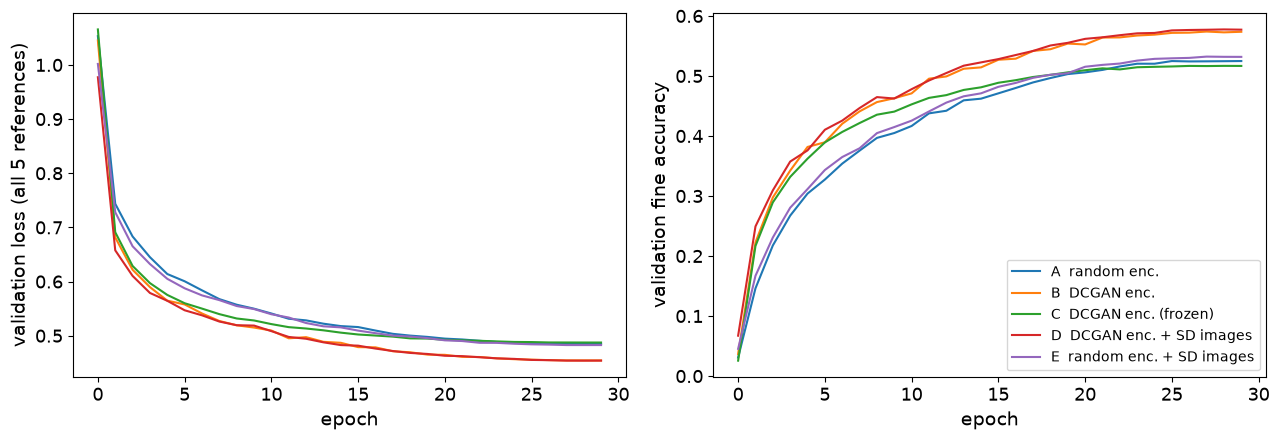

In [18]:
import pandas as pd
METRICS = ["fine_acc", "coarse_acc", "category_consistency", "exact_match", "bleu4", "cider"]   # columns of the result tables

def summarise(split, beam):
    """Evaluate every experiment's models on `split` with beam width `beam` (1 = greedy);
    returns (table of mean +- std over the seeds, per-seed metric dicts)."""
    rows, per_seed = [], {}
    for key in EXPERIMENTS:
        res = [evaluate(MODELS[(key, s)], split, beam)[0] for s in SEEDS]
        per_seed[key] = res
        rows.append({"model": key, **{m: f"{np.mean([r[m] for r in res]):.3f} ± {np.std([r[m] for r in res]):.3f}" for m in METRICS}})
    return pd.DataFrame(rows).set_index("model"), per_seed

val_table, val_per_seed = summarise("val", beam=1)   # beam=1: greedy decoding
print("Validation set, greedy decoding, mean ± std over 3 seeds")
display(val_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for key in EXPERIMENTS:
    for ax, metric, label in zip(axes, ("val_loss", "val_fine_acc"), ("validation loss (all 5 references)", "validation fine accuracy")):
        ax.plot(np.mean([RUNS[(key, s)]["history"][metric] for s in SEEDS], 0), label=key)
        ax.set(xlabel="epoch", ylabel=label)
axes[1].legend(fontsize=PLOT_FONT - 3)
plt.tight_layout(); fig.savefig(OUT_DIR / "captioner_val_curves.png", dpi=150); plt.show()


In [19]:
# Domain-gap diagnostic (not training): model B (every seed, greedy decoding) never saw synthetic images, so its accuracy on them
# versus on real validation images shows how far the synthetic images are from real CIFAR-100.
# ---------------------------------------------------------------- Parameters
N_GAP_IMAGES = 5000   # random synthetic images used for the comparison
GAP_SEED = 0          # seed of that random choice, so the same subset is used on every run
# ------------------------------------------------------------------------------
if SD_IMAGES is not None:
    sd_idx_rng = np.random.default_rng(GAP_SEED)
    sub = np.sort(sd_idx_rng.choice(len(SD_IMAGES), N_GAP_IMAGES, replace=False))
    gaps = []
    for s in SEEDS:
        hyps = predict_captions(MODELS[("B  DCGAN enc.", s)], X_SD[sub])
        gaps.append(np.mean([parse_caption(h)[0] == SD_FINE[j] for h, j in zip(hyps, sub)]))
    real_acc = np.mean([val_per_seed["B  DCGAN enc."][i]["fine_acc"] for i in range(len(SEEDS))])
    print(f"Model B (trained on real images only): fine accuracy on real val images {real_acc:.1%}  vs  on Stable Diffusion images {np.mean(gaps):.1%}")


Model B (trained on real images only): fine accuracy on real val images 57.4%  vs  on Stable Diffusion images 36.5%


## 8. Test-set evaluation

The test set (12,000 real images, 120 per class) is used only for the final report, after every model has been trained and its best epoch chosen on the validation set; no training or selection decision uses it. We report all five configurations rather than picking the best one on test, with greedy decoding and with beam search (beam 3).

In [20]:
# ---------------------------------------------------------------- Parameters
BEAM_WIDTH = 3   # beam search width of the second test table (the first table uses greedy decoding, beam 1)
# ------------------------------------------------------------------------------
test_greedy, test_greedy_seed = summarise("test", beam=1)
test_beam, test_beam_seed = summarise("test", beam=BEAM_WIDTH)
print("TEST set, greedy decoding, mean ± std over 3 seeds"); display(test_greedy)
print(f"TEST set, beam search ({BEAM_WIDTH}), mean ± std over 3 seeds"); display(test_beam)

import json
(OUT_DIR / "results.json").write_text(json.dumps({
    "val_greedy": val_per_seed, "test_greedy": test_greedy_seed, "test_beam3": test_beam_seed,
    "best_epochs": {f"{k}|{s}": RUNS[(k, s)]["best_epoch"] for k, s in RUNS}, "cap_cfg": CAP_CFG, "seeds": SEEDS}, indent=1))


TEST set, greedy decoding, mean ± std over 3 seeds


,fine_acc,coarse_acc,category_consistency,exact_match,bleu4,cider
model,,,,,,
A random enc.,0.518 ± 0.003,0.650 ± 0.002,1.000 ± 0.000,0.518 ± 0.003,0.813 ± 0.001,2.808 ± 0.017
B DCGAN enc.,0.572 ± 0.001,0.698 ± 0.001,1.000 ± 0.000,0.572 ± 0.001,0.840 ± 0.003,3.073 ± 0.003
C DCGAN enc. (frozen),0.516 ± 0.001,0.643 ± 0.001,1.000 ± 0.000,0.516 ± 0.001,0.815 ± 0.001,2.791 ± 0.004
D DCGAN enc. + SD images,0.575 ± 0.002,0.702 ± 0.002,1.000 ± 0.000,0.575 ± 0.002,0.837 ± 0.001,3.087 ± 0.011
E random enc. + SD images,0.530 ± 0.004,0.660 ± 0.004,1.000 ± 0.000,0.530 ± 0.004,0.819 ± 0.003,2.864 ± 0.030


TEST set, beam search (3), mean ± std over 3 seeds


,fine_acc,coarse_acc,category_consistency,exact_match,bleu4,cider
model,,,,,,
A random enc.,0.521 ± 0.003,0.652 ± 0.003,1.000 ± 0.000,0.521 ± 0.003,0.817 ± 0.001,2.835 ± 0.024
B DCGAN enc.,0.577 ± 0.001,0.701 ± 0.001,1.000 ± 0.000,0.577 ± 0.001,0.844 ± 0.002,3.122 ± 0.003
C DCGAN enc. (frozen),0.520 ± 0.001,0.645 ± 0.001,1.000 ± 0.000,0.520 ± 0.001,0.819 ± 0.002,2.820 ± 0.004
D DCGAN enc. + SD images,0.578 ± 0.002,0.703 ± 0.002,1.000 ± 0.000,0.578 ± 0.002,0.842 ± 0.001,3.135 ± 0.013
E random enc. + SD images,0.532 ± 0.004,0.663 ± 0.004,1.000 ± 0.000,0.532 ± 0.004,0.823 ± 0.003,2.893 ± 0.024


15225

### Example captions

Random test images, captioned by the best configuration (by validation fine accuracy, seed 0). Green: correct class, red: wrong class.

best configuration on validation: D  DCGAN enc. + SD images


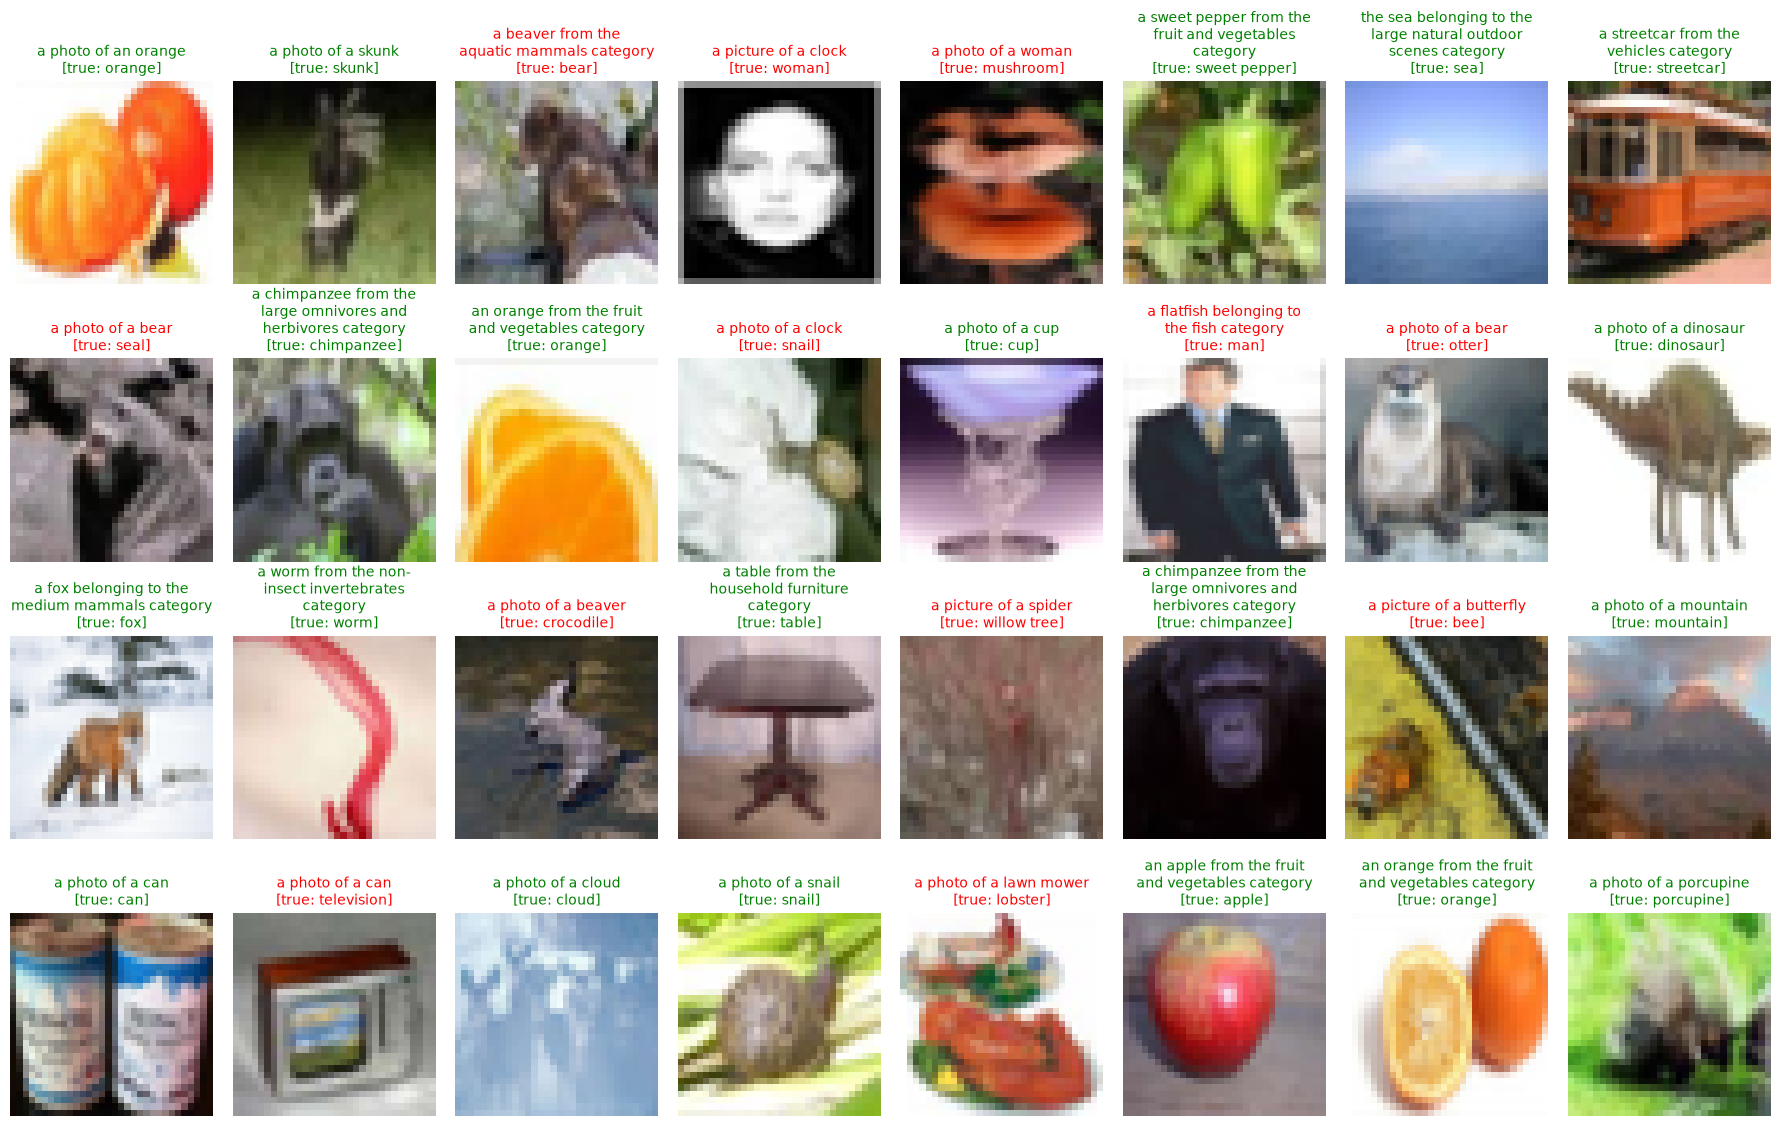

In [20]:
# ---------------------------------------------------------------- Parameters
CAPTION_WRAP = 24   # characters per line when a caption is wrapped above its image
N_EXAMPLES = 32     # random test images shown (a 4 x 8 grid)
EXAMPLE_SEED = 7    # seed of the random choice, so the same images are shown on every run
# ------------------------------------------------------------------------------
import textwrap
# the configuration with the best mean validation fine accuracy (chosen on validation, not on test)
best_key = max(EXPERIMENTS, key=lambda k: np.mean([r["fine_acc"] for r in val_per_seed[k]]))
best_model = MODELS[(best_key, 0)]
_, test_caps, test_pred = evaluate(best_model, "test", beam=1)
print("best configuration on validation:", best_key)

rng = np.random.default_rng(EXAMPLE_SEED)
pick = rng.choice(len(SPLITS["test"]), N_EXAMPLES, replace=False)
fig, axes = plt.subplots(4, 8, figsize=(18, 11.5))
for ax, j in zip(axes.ravel(), pick):
    i = SPLITS["test"][j]
    ok = test_pred[j] == fine_labels[i]
    ax.imshow(images[i]); ax.axis("off")
    ax.set_title(textwrap.fill(test_caps[j], CAPTION_WRAP) + f"\n[true: {FINE_PHRASE[fine_labels[i]]}]", fontsize=PLOT_FONT - 3, color="green" if ok else "red")
plt.tight_layout(); fig.savefig(OUT_DIR / "test_examples.png", dpi=150, bbox_inches="tight"); plt.show()


### Error analysis

Which classes does the captioner get right, and which does it confuse?

hardest classes:  otter (1%), seal (27%), man (28%), snake (32%), rabbit (32%), mouse (35%), squirrel (35%), lizard (36%)
easiest classes:  road (92%), skunk (89%), plain (88%), wardrobe (88%), sunflower (84%), chair (82%), palm tree (82%), motorcycle (80%)

most frequent confusions (true -> predicted):
  maple tree     -> oak tree        24x   (same coarse category)
  bus            -> streetcar       24x
  oak tree       -> maple tree      21x   (same coarse category)
  whale          -> dolphin         20x   (same coarse category)
  dolphin        -> whale           19x   (same coarse category)
  bowl           -> plate           19x   (same coarse category)
  castle         -> house           19x   (same coarse category)
  man            -> boy             17x   (same coarse category)
  whale          -> shark           17x
  woman          -> girl            16x   (same coarse category)

captions naming no class at all: 0.00%
superclasses with the largest gap between coarse and fi

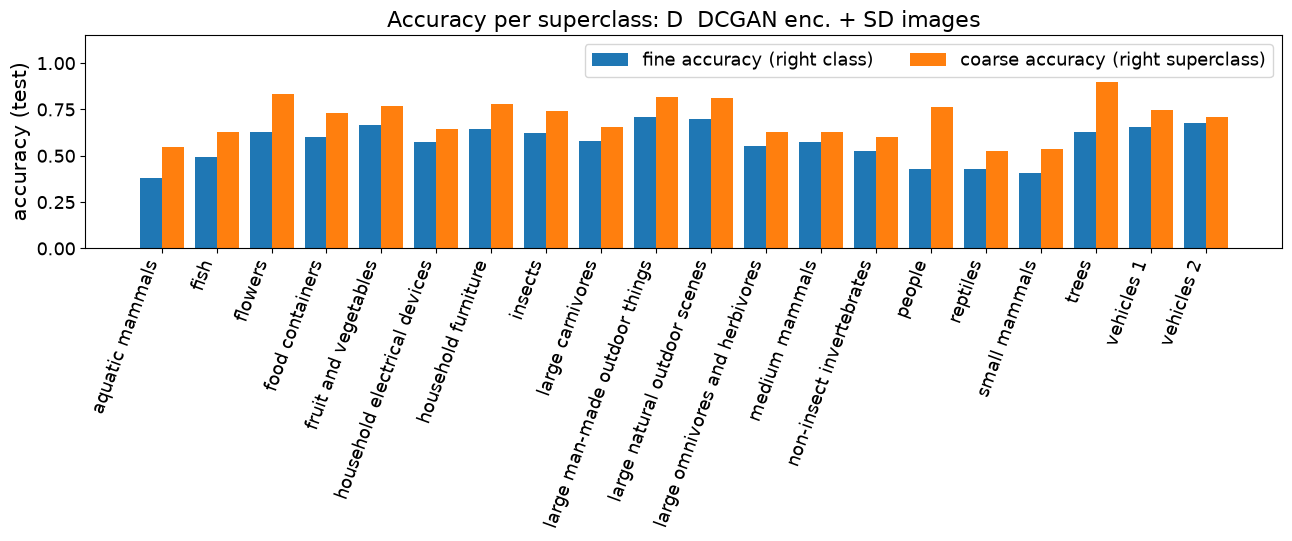

In [21]:
# ---------------------------------------------------------------- Parameters
N_LISTED = 8       # hardest and easiest classes listed
N_CONFUSIONS = 10  # most frequent confusions listed
# ------------------------------------------------------------------------------
true = fine_labels[SPLITS["test"]]
acc_per_class = np.array([np.mean(test_pred[true == c] == c) for c in range(100)])
order = np.argsort(acc_per_class)
print("hardest classes: ", ", ".join(f"{FINE_PHRASE[c]} ({acc_per_class[c]:.0%})" for c in order[:N_LISTED]))
print("easiest classes: ", ", ".join(f"{FINE_PHRASE[c]} ({acc_per_class[c]:.0%})" for c in order[::-1][:N_LISTED]))

conf = Counter((int(t), int(p)) for t, p in zip(true, test_pred) if t != p and p >= 0)
print("\nmost frequent confusions (true -> predicted):")
for (t, p), n in conf.most_common(N_CONFUSIONS):
    print(f"  {FINE_PHRASE[t]:14s} -> {FINE_PHRASE[p]:14s} {n:3d}x" + ("   (same coarse category)" if FINE_TO_COARSE[t] == FINE_TO_COARSE[p] else ""))
print(f"\ncaptions naming no class at all: {np.mean(test_pred < 0):.2%}")

# per superclass (20 groups of test images): fine accuracy = the caption names the right class,
# coarse accuracy = the named class belongs to the right superclass (captions that name no class, -1, are mapped to class 0 here; ~0% above)
test_coarse = coarse_labels[SPLITS["test"]]
fine_acc_sc = np.array([np.mean(test_pred[test_coarse == k] == true[test_coarse == k]) for k in range(20)])
coarse_acc = np.array([np.mean(FINE_TO_COARSE[np.maximum(test_pred, 0)][test_coarse == k] == k) for k in range(20)])
print("superclasses with the largest gap between coarse and fine accuracy (errors inside the superclass):")
for k in np.argsort(fine_acc_sc - coarse_acc)[:5]:
    print(f"  {COARSE_NAMES[k].replace('_', ' '):34s} fine {fine_acc_sc[k]:.0%} | coarse {coarse_acc[k]:.0%} | gap {coarse_acc[k] - fine_acc_sc[k]:.0%}")

fig, ax = plt.subplots(figsize=(13, 5.6))
w = 0.4   # bar width: two bars per superclass
ax.bar(np.arange(20) - w / 2, fine_acc_sc, w, label="fine accuracy (right class)")
ax.bar(np.arange(20) + w / 2, coarse_acc, w, label="coarse accuracy (right superclass)")
ax.set_xticks(range(20)); ax.set_xticklabels([COARSE_NAMES[k].replace("_", " ") for k in range(20)], rotation=70, ha="right", fontsize=PLOT_FONT)   # keeps "vehicles 1" and "vehicles 2" apart
ax.set_ylabel("accuracy (test)", fontsize=PLOT_FONT + 2); ax.set_ylim(0, 1.15); ax.tick_params(axis="y", labelsize=PLOT_FONT)
ax.set_title(f"Accuracy per superclass: {best_key}", fontsize=PLOT_FONT + 3)
ax.legend(fontsize=PLOT_FONT, loc="upper right", ncol=2)   # above the bars, so it hides nothing
plt.tight_layout(); fig.savefig(OUT_DIR / "test_coarse_accuracy.png", dpi=150); plt.show()


### Where does the decoder look? [Extra Analysis]

Cross-attention of the last decoder layer, averaged over heads: for the word that names the class, how much weight does it put on each of the 4×4 grid cells of the image?

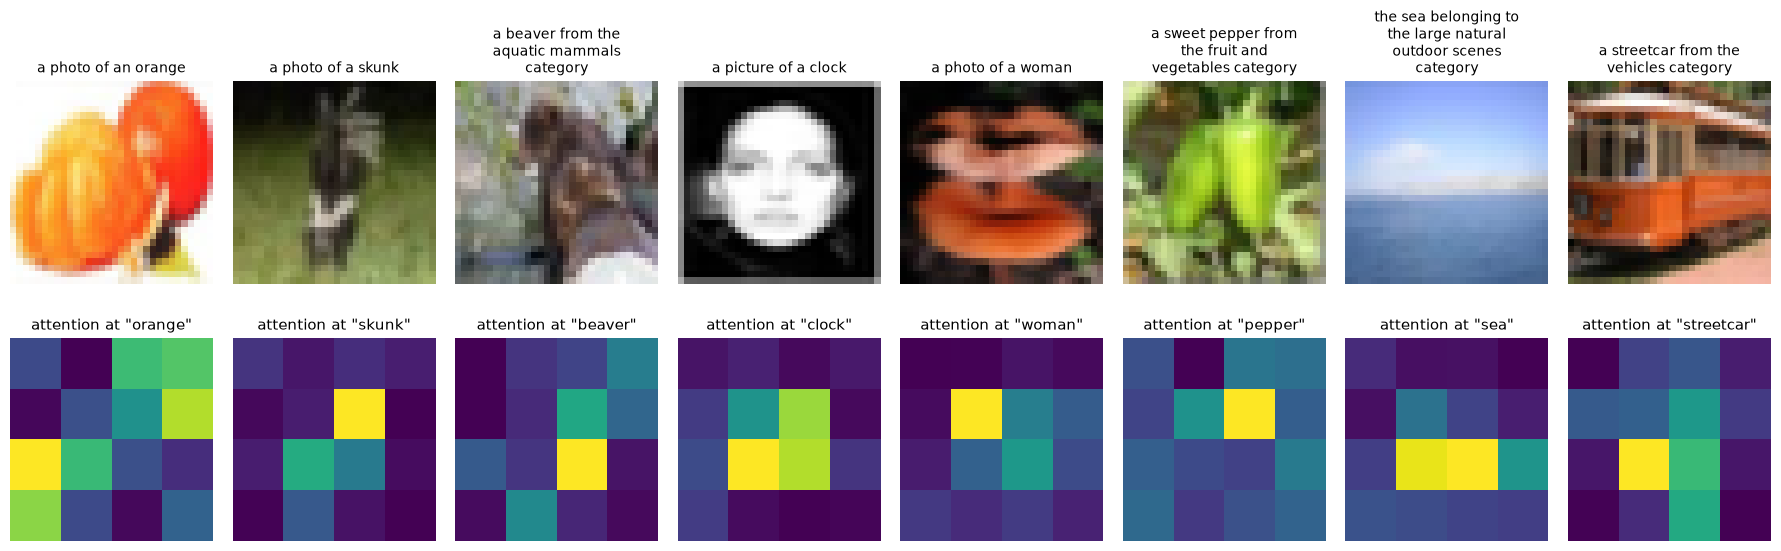

In [22]:
# ---------------------------------------------------------------- Parameters
ATTN_WRAP = 22   # characters per line of the caption above each image
N_ATTN = 8   # test images shown (the first N_ATTN of the example images above)
# ------------------------------------------------------------------------------
import textwrap
best_model.eval()
sel = pick[:N_ATTN]
x = X["test"][sel].to(DEVICE)
fig, axes = plt.subplots(2, 8, figsize=(18, 6.2))
with torch.no_grad():
    caps = [test_caps[j] for j in sel]
    ids = torch.tensor([vocab.encode(c, MAX_LEN) for c in caps], device=DEVICE)
    best_model(x, ids[:, :-1])   # teacher-forced pass over the generated captions, only to make the last layer store its cross-attention map
    w = best_model.layers[-1].cross_weights.mean(1)            # (B, T, 16)
for r, j in enumerate(sel):
    toks = ids[r].tolist()
    T = toks.index(vocab.eos_id) if vocab.eos_id in toks else len(toks)
    words = [vocab.itos[t] for t in toks[1:T]]
    # position of the last word of the class name (the query row that predicts it); len() of the slice handles names at the caption end
    fine_tok = next((k + len(words[k:k + L]) - 1 for k in range(len(words)) for L in range(_MAXL, 0, -1)
                     if tuple(words[k:k + L]) in FINE_TOK), 0)
    axes[0, r].imshow(images[SPLITS["test"][j]]); axes[0, r].axis("off"); axes[0, r].set_title(textwrap.fill(caps[r], ATTN_WRAP), fontsize=PLOT_FONT - 3)
    axes[1, r].imshow(w[r, fine_tok].view(4, 4).cpu(), cmap="viridis"); axes[1, r].axis("off")
    axes[1, r].set_title(f'attention at "{words[fine_tok]}"', fontsize=PLOT_FONT - 2)
plt.tight_layout(); fig.savefig(OUT_DIR / "cross_attention.png", dpi=150, bbox_inches="tight"); plt.show()
